# XAUUSD Multiclass Prediction — Versi Optimasi
Window=96, Horizon=6 | 57 Fitur | Conv-GRU | TimeSeriesSplit CV + LR Finder

> **Catatan RAM (16GB-friendly):** versi ini tidak lagi menyimpan array window
> 3D penuh (`X`) di RAM — yang tadinya menduplikasi tiap baris candle sebanyak
> `WINDOW_SIZE` (96) kali dan bisa membengkak puluhan GB untuk data multi-tahun.
> Sekarang hanya array 2D mentah (`feats_base`) yang disimpan, dan window
> dibuat on-the-fly oleh `WindowDataset` saat training/inference. Hasil
> training identik, RAM yang dipakai jauh lebih kecil.


In [1]:
import torch
import dukascopy_python
from dukascopy_python.instruments import INSTRUMENT_FX_METALS_XAU_USD
import datetime
import pandas as pd
import numpy as np
import gc

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# SPEEDUP: cuDNN akan benchmark & pilih algoritma conv tercepat untuk ukuran
# input yang tetap (window/batch kita selalu sama tiap step) -- cuma perlu
# di-set sekali di awal notebook, sebelum training mulai. Tidak mengubah
# hasil training sama sekali, cuma mempercepat pemilihan kernel conv di GPU.
if device == "cuda":
    torch.backends.cudnn.benchmark = True

# ================= KONFIGURASI DUKASCOPY =================
# Tidak perlu API key / akun sama sekali — Dukascopy menyediakan history
# gratis untuk publik (data sejak awal 2000-an untuk XAU/USD).
INSTRUMENT = INSTRUMENT_FX_METALS_XAU_USD   # "XAU/USD" (Gold vs USD), setara XAUUSD di MT5
OFFER_SIDE = dukascopy_python.OFFER_SIDE_BID


Device: cuda


In [2]:
# Dukascopy tidak butuh initialize/login seperti MT5 — cukup tes fetch kecil untuk memastikan koneksi jalan
_test = dukascopy_python.fetch(
    INSTRUMENT,
    dukascopy_python.INTERVAL_HOUR_1,
    OFFER_SIDE,
    datetime.datetime.utcnow() - datetime.timedelta(days=3),
    datetime.datetime.utcnow(),
)

if _test is not None and len(_test) > 0:
    print("Berhasil terhubung ke Dukascopy (tidak perlu API key / akun).")
    print(_test.tail(3))
else:
    print("Gagal mengambil data test dari Dukascopy — cek koneksi internet Anda.")


C:\Users\ANDRA\AppData\Local\Temp\ipykernel_7704\1564275067.py:6: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  datetime.datetime.utcnow() - datetime.timedelta(days=3),
C:\Users\ANDRA\AppData\Local\Temp\ipykernel_7704\1564275067.py:7: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  datetime.datetime.utcnow(),


Berhasil terhubung ke Dukascopy (tidak perlu API key / akun).
                               open      high       low     close   volume
timestamp                                                                 
2026-07-03 14:00:00+00:00  4164.305  4170.965  4155.085  4169.485  1.32987
2026-07-03 15:00:00+00:00  4169.515  4174.265  4164.265  4164.545  0.96954
2026-07-03 16:00:00+00:00  4164.565  4176.055  4162.535  4175.245  0.67476


## 1. Feature Engineering

In [3]:
from ta.volatility import BollingerBands
def add_ema(df):
    df["ema20"]  = df["close"].ewm(span=20).mean()
    df["ema50"]  = df["close"].ewm(span=50).mean()
    df["ema200"] = df["close"].ewm(span=200).mean()
    df["ema20_dist"]  = (df["close"] - df["ema20"])  / df["ema20"]
    df["ema50_dist"]  = (df["close"] - df["ema50"])  / df["ema50"]
    df["ema200_dist"] = (df["close"] - df["ema200"]) / df["ema200"]
    return df

def add_bb(df):

    bb = BollingerBands(df["close"], window=20)

    df["bb_upper"] = bb.bollinger_hband()
    df["bb_lower"] = bb.bollinger_lband()
    df["bb_middle"] = bb.bollinger_mavg()

    df["bb_position"] = (
        (df["close"]-df["bb_lower"]) /
        (df["bb_upper"]-df["bb_lower"]+1e-8)
    )

    return df

def add_macd(df):
    ema12 = df["close"].ewm(span=12).mean()
    ema26 = df["close"].ewm(span=26).mean()
    df["macd"]        = (ema12 - ema26) / df["close"]
    df["macd_signal"] = df["macd"].ewm(span=9).mean()
    return df

def add_rsi(df, period=14):
    # Hitung selisih close, pertahankan indeks asli df
    delta = df["close"].diff()
    
    # Gunakan np.where tetapi langsung bungkus dengan Series bernilai indeks sama dengan df
    gain = pd.Series(np.where(delta > 0, delta, 0.0), index=df.index)
    loss = pd.Series(np.where(delta < 0, -delta, 0.0), index=df.index)
    
    # Menggunakan Wilder's Exponential Moving Average (Sama seperti MT5/TradingView)
    # alpha=1/period adalah standar kalkulasi RSI Wilder
    avg_gain = gain.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    
    rs = avg_gain / (avg_loss + 1e-9)
    df["rsi"] = 100 - (100 / (1 + rs))
    
    # Opsional: langsung normalisasi ke skala -1 s.d 1 agar Conv-GRU kamu lebih stabil
    df["rsi_norm"] = (df["rsi"] - 50) / 50
    
    return df

def add_atr(df, period=14):
    hl  = df["high"] - df["low"]
    hc  = np.abs(df["high"] - df["close"].shift())
    lc  = np.abs(df["low"]  - df["close"].shift())
    tr  = np.maximum(hl, np.maximum(hc, lc))
    df["atr"] = pd.Series(tr).rolling(period).mean()
    return df

def calculate_volume_profile_rolling(df, window=60, n_bins=10):
    """
    Menghitung jarak harga saat ini ke Point of Control (POC) berdasarkan Rolling Window.
    """
    poc_distances = np.zeros(len(df))
    
    # Konversi ke numpy array untuk kecepatan komputasi
    closes = df['close'].values
    volumes = df['tick_volume'].values
    
    for i in range(window, len(df)):
        # Ambil window historis
        window_closes = closes[i-window:i]
        window_volumes = volumes[i-window:i]
        
        # Buat Price Bins berdasarkan harga tertinggi dan terendah di window tersebut
        min_p, max_p = window_closes.min(), window_closes.max()
        if max_p == min_p:
            poc_distances[i] = 0
            continue
            
        bins = np.linspace(min_p, max_p, n_bins + 1)
        
        # Hitung volume digital (horizontal volume) per bin
        # Mencari tahu setiap close masuk ke bin mana
        bin_indices = np.digitize(window_closes, bins) - 1
        bin_indices = np.clip(bin_indices, 0, n_bins - 1)
        
        bin_volumes = np.zeros(n_bins)
        for idx, vol in zip(bin_indices, window_volumes):
            bin_volumes[idx] += vol
            
        # Temukan bin dengan volume terbesar (Point of Control / POC)
        poc_bin_idx = np.argmax(bin_volumes)
        # Ambil nilai tengah harga dari bin POC tersebut
        poc_price = (bins[poc_bin_idx] + bins[poc_bin_idx + 1]) / 2
        
        # Hitung jarak relatif % harga close saat ini ke POC
        poc_distances[i] = (closes[i] - poc_price) / poc_price
        
    return poc_distances

def calculate_price_density_rolling(df, window=120, tolerance_atr_mult=0.5):
    """
    Menghitung seberapa sering area harga saat ini dijadikan titik pantulan (High/Low) di masa lalu.
    """
    density_counts = np.zeros(len(df))
    
    closes = df['close'].values
    highs = df['high'].values
    lows = df['low'].values
    atrs = df['atr'].values  # Pastikan kamu sudah menghitung kolom 'atr' sebelumnya
    
    for i in range(window, len(df)):
        current_close = closes[i]
        current_atr = atrs[i]
        
        # Tentukan batas toleransi area S/R berdasarkan volatilitas (ATR)
        # Supaya dinamis mengikuti kondisi market XAUUSD
        buffer = current_atr * tolerance_atr_mult
        
        # Ambil data High dan Low historis dalam window
        window_highs = highs[i-window:i]
        window_lows = lows[i-window:i]
        
        # Hitung berapa banyak High/Low masa lalu yang nempel di harga Close saat ini
        high_hits = np.sum((window_highs >= current_close - buffer) & (window_highs <= current_close + buffer))
        low_hits = np.sum((window_lows >= current_close - buffer) & (window_lows <= current_close + buffer))
        
        # Total interaksi harga (Price Density)
        density_counts[i] = high_hits + low_hits
        
    # Normalisasi agar skalanya sehat masuk ke model (Z-Score rolling sederhana)
    # Atau bisa dibagi dengan 'window' agar menghasilkan rasio 0 sampai 1
    return density_counts / (window * 2)

def calculate_daily_anchors(df_intraday):
    """
    Menghitung High, Low, PP, R1, dan S1 dari hari sebelumnya (Yesterday).
    Asumsi: df_intraday memiliki DatetimeIndex.
    """
    # 1. Resample data intraday ke skala Harian (Daily)
    daily = df_intraday['close'].resample('D').ohlc()
    
    # Masukkan data High dan Low harian murni
    daily['high'] = df_intraday['high'].resample('D').max()
    daily['low'] = df_intraday['low'].resample('D').min()
    
    # Drop hari yang tidak ada transaksi (misal akhir pekan)
    daily = daily.dropna()
    
    # 2. Geser data (SHIFT 1) agar hari ini menggunakan data "HARI KEMARIN"
    # Ini krusial agar model tidak mencontek data hari ini!
    daily['prev_high'] = daily['high'].shift(1)
    daily['prev_low'] = daily['low'].shift(1)
    daily['prev_close'] = daily['close'].shift(1)
    
    # 3. Hitung Rumus Pivot Point Standar berdasarkan data kemarin
    daily['PP'] = (daily['prev_high'] + daily['prev_low'] + daily['prev_close']) / 3
    daily['R1'] = (2 * daily['PP']) - daily['prev_low']
    daily['S1'] = (2 * daily['PP']) - daily['prev_high']
    
    # Kita hanya butuh kolom jangkar ini saja
    anchor_columns = ['prev_high', 'prev_low', 'PP', 'R1', 'S1']
    return daily[anchor_columns]

def generate_anchor_distance_features(df):
    """
    Menggabungkan jangkar harian ke data intraday dan menghitung jarak relatif %.
    """
    # FIX KRITIS: df.index sebelumnya RangeIndex (0,1,2,...) hasil pd.concat,
    # BUKAN timestamp asli. `pd.to_datetime(df.index)` lama mengubah angka baris
    # jadi nanodetik sejak epoch 1970-01-01 — semua anchor harian (PP/R1/S1) dan
    # fitur turunannya jadi dihitung dari "tanggal" yang salah total.
    # Sekarang index dibangun dari kolom 'time' (unix seconds) yang benar.
    df = df.copy()
    df.index = pd.to_datetime(df['time'], unit='s')

    # Buat kolom pembantu berupa 'tanggal' saja untuk merge
    df['date_key'] = df.index.date
    
    # Hitung jangkar harian
    daily_anchors = calculate_daily_anchors(df)
    daily_anchors.index = daily_anchors.index.date # Ubah index menjadi tanggal saja
    
    # Gabungkan (Merge) data intraday dengan data jangkar harian
    df = df.merge(daily_anchors, left_on='date_key', right_index=True, how='left')
    
    # Isu hari Senin: Karena shift(1) hari Minggu kosong, kita forward fill (ffill) jika ada bolong
    df[['prev_high', 'prev_low', 'PP', 'R1', 'S1']] = df[['prev_high', 'prev_low', 'PP', 'R1', 'S1']].ffill()
    
    # 4. HITUNG JARAK RELATIF (%)
    # Rumus: (Harga Sekarang - Harga Jangkar) / Harga Jangkar
    df['prev_day_high_dist'] = (df['close'] - df['prev_high']) / df['prev_high']
    df['prev_day_low_dist']  = (df['close'] - df['prev_low']) / df['prev_low']
    
    df['pivot_point_dist']   = (df['close'] - df['PP']) / df['PP']
    df['r1_dist']            = (df['close'] - df['R1']) / df['R1']
    df['s1_dist']            = (df['close'] - df['S1']) / df['S1']
    
    # Hapus kolom temporary agar dataset bersih kembali
    df = df.drop(columns=['date_key', 'prev_high', 'prev_low', 'PP', 'R1', 'S1'])
    
    # Isi data kosong di baris-baris awal dengan 0
    return df.fillna(0)

def calculate_volume_zscore(df, window=20):
    """
    Menghitung seberapa ekstrem volume saat ini dibanding rata-rata historisnya.
    """
    # 1. Hitung rata-rata rolling (Mean) dari volume
    roll_mean = df['tick_volume'].rolling(window=window).mean()
    
    # 2. Hitung standar deviasi rolling (Std Dev) dari volume
    roll_std = df['tick_volume'].rolling(window=window).std()
    
    # 3. Hitung Z-Score (tambahkan epsilon 1e-8 untuk menghindari pembagian dengan nol)
    volume_zscore = (df['tick_volume'] - roll_mean) / (roll_std + 1e-8)
    
    # Isi nilai NaN di awal window dengan 0
    return volume_zscore.fillna(0)

def calculate_atr_zscore(df, window=20):
    """
    Menghitung ekspansi atau kompresi volatilitas berdasarkan Z-Score dari ATR.
    Pastikan kolom 'atr' sudah ada di DataFrame kamu.
    """
    # 1. Hitung rata-rata rolling dari ATR
    roll_mean_atr = df['atr'].rolling(window=window).mean()
    
    # 2. Hitung standar deviasi rolling dari ATR
    roll_std_atr = df['atr'].rolling(window=window).std()
    
    # 3. Hitung Z-Score untuk mendeteksi spread expansion
    atr_zscore = (df['atr'] - roll_mean_atr) / (roll_std_atr + 1e-8)
    
    return atr_zscore.fillna(0)

def calculate_session_volume_zscore(df, window_days=20):
    """
    Menghitung Z-Score volume berdasarkan jam yang sama di hari-hari sebelumnya.
    Sangat kuat untuk menjinakkan bias waktu pada XAUUSD.
    """
    # Pastikan index berupa datetime
    df['hour_group'] = df.index.hour
    
    # Hitung rata-rata dan std dev per jam menggunakan transform rolling harian
    # Catatan: Asumsi data intraday lengkap. Pendekatan praktis:
    roll_mean = df.groupby('hour_group')['tick_volume'].transform(lambda x: x.rolling(window=window_days, min_periods=1).mean())
    roll_std = df.groupby('hour_group')['tick_volume'].transform(lambda x: x.rolling(window=window_days, min_periods=1).std())
    
    session_zscore = (df['tick_volume'] - roll_mean) / (roll_std + 1e-8)
    
    df = df.drop(columns=['hour_group'])
    return session_zscore.fillna(0)


def create_features(df):
    import numpy as np
    import pandas as pd

    # Returns
    df["return"] = df["close"].pct_change()
    df["ret_1"]  = df["close"].pct_change(1)
    df["ret_2"]  = df["close"].pct_change(2)
    df["ret_3"]  = df["close"].pct_change(3)
    df["ret_6"]  = df["close"].pct_change(6)
    df["ret_12"] = df["close"].pct_change(12)
    df["ret_24"] = df["close"].pct_change(24)

    df = add_rsi(df)
    df = add_atr(df)
    df = add_ema(df)
    df = add_bb(df)
    df = add_macd(df)

    # Volatility
    df["volatility"] = df["return"].rolling(20).std()

    # Candle pattern (normalized)
    df["body"]       = (df["close"] - df["open"]) / df["close"]
    df["upper_wick"] = (df["high"] - np.maximum(df["open"], df["close"])) / df["close"]
    df["lower_wick"] = (np.minimum(df["open"], df["close"]) - df["low"]) / df["close"]

    # Time encoding & Day encoding
    datetime_col = pd.to_datetime(df["time"], unit="s")
    hour = datetime_col.dt.hour
    day_of_week = datetime_col.dt.dayofweek # 0=Senin, 6=Minggu

    # 1. Sesi Asia (06:00 - 14:00)
    df["sesi_asia"] = ((hour >= 6) & (hour <= 14)).astype(int)

    # 2. Sesi Eropa/London (14:00 - 22:00)
    df["sesi_eropa"] = ((hour >= 14) & (hour <= 22)).astype(int)

    # 3. Sesi Amerika / NY (19:00 - 03:00) -> Menggunakan OR (|) karena menyeberang tengah malam
    df["sesi_amerika"] = ((hour >= 19) | (hour <= 3)).astype(int)

    # 4. Sesi Golden / Overlap London-NY (19:00 - 22:00) -> Sangat penting untuk XAUUSD
    df["sesi_golden"] = ((hour >= 19) & (hour <= 22)).astype(int)
    
    # Sine/Cosine Encoding untuk Jam (Siklus 24 Jam)
    df["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    df["hour_cos"] = np.cos(2 * np.pi * hour / 24)

    # Sine/Cosine Encoding untuk Hari (Siklus 7 Hari - Sangat penting untuk anomali Senin/Jumat)
    df["day_sin"] = np.sin(2 * np.pi * day_of_week / 7)
    df["day_cos"] = np.cos(2 * np.pi * day_of_week / 7)

    # Momentum
    df["momentum_3"] = (df["close"] - df["close"].shift(3)) / df["close"]
    df["momentum_6"] = (df["close"] - df["close"].shift(6)) / df["close"]

    # Volume (hanya ratio — hapus vol_ma absolut)
    df["vol_ma"]    = df["tick_volume"].rolling(10).mean()
    df["vol_ratio"] = df["tick_volume"] / (df["vol_ma"] + 1e-9)

    # Bar strength
    df["bar_strength"] = np.abs(df["close"] - df["open"]) / (df["high"] - df["low"] + 1e-8)

    # Garman-Klass Volatility
    inside_sqrt = 0.5 * (np.log(df["high"] / df["low"])) ** 2 - (
        2 * np.log(2) - 1) * (np.log(df["close"] / df["open"])) ** 2
    df["vol_gk"] = np.sqrt(np.clip(inside_sqrt, 0, None))

    # Vol Z-Score (lookback 96)
    vol_m = df["vol_gk"].rolling(window=96).mean()
    vol_s = df["vol_gk"].rolling(window=96).std()
    df["vol_zscore"] = (df["vol_gk"] - vol_m) / (vol_s + 1e-8)

    # NATR = ATR (sudah / close di add_atr)
    df["natr"] = df["atr"] / df["close"]

    # Streak
    is_bull = (df["close"] > df["open"]).astype(int)
    is_bear = (df["close"] < df["open"]).astype(int)
    df["bull_streak"] = (is_bull.groupby((is_bull != is_bull.shift()).cumsum()).cumsum()) * is_bull
    df["bear_streak"] = (is_bear.groupby((is_bear != is_bear.shift()).cumsum()).cumsum()) * is_bear

    # Price position 96
    rolling_min = df["low"].rolling(window=96).min()
    rolling_max = df["high"].rolling(window=96).max()
    df["price_position_96"] = (df["close"] - rolling_min) / (rolling_max - rolling_min + 1e-8)

    # ── Divergence RSI ──
    df['rsi_slope_3']  = df['rsi'].diff(3)   # dipakai khusus untuk rsi_div
    df['price_slope']  = df['close'].pct_change(3)
    df['rsi_div']      = df['rsi_slope_3'] - df['price_slope'] * 100

    # ── Volume Confirmation ──
    df['vol_confirm'] = df['vol_ratio'] * df['body']

    # ── ATR Ratio (volatility regime) ──
    df['atr_ratio'] = df['atr'] / df['atr'].rolling(50).mean()

    # ── Candle efficiency ──
    df['efficiency'] = (df['close'] - df['open']).abs() / \
                       (df['high'] - df['low'] + 1e-8)

    # ── Higher timeframe trend (simulasi dari M5) ──
    df['trend_1h'] = np.sign(df['close'] - df['close'].ewm(span=12).mean())
    df['trend_4h'] = np.sign(df['close'] - df['close'].ewm(span=48).mean())

    df['poc_dist'] = calculate_volume_profile_rolling(df, window=60, n_bins=10)

    df['price_density'] = calculate_price_density_rolling(df, window=120, tolerance_atr_mult=0.5)

    df = generate_anchor_distance_features(df)

    df['volume_zscore'] = calculate_volume_zscore(df, window=20)

    df['atr_zscore'] = calculate_atr_zscore(df, window=20)

    df['volume_zscore_modular'] = calculate_session_volume_zscore(df, window_days=14)

    # ── Perbaikan Rumus FVG Khusus Scalping (Konsisten Menggunakan Huruf Kecil) ──
    
    # 1. Hitung ATR (Volatilitas Lokal) untuk menyaring noise
    df['tr'] = np.maximum(df['high'] - df['low'], 
                          np.maximum((df['high'] - df['close'].shift(1)).abs(), 
                                     (df['low'] - df['close'].shift(1)).abs()))
    df['atr_14'] = df['tr'].rolling(window=14).mean()

    df['tr_percentage'] = df['tr'] / df['close']
    df['atr_14_percentage'] = df['atr_14'] / df['close']

    # 2. Rumus Bullish FVG (Sudut Pandang Candle Tengah t)
    df['bullish_fvg_gap'] = df['low']        - df['high'].shift(2)   # c=t (current), a=t-2

    df['valid_scalp_fvg'] = ((df['bullish_fvg_gap'] > 0) & (df['bullish_fvg_gap'] > (df['atr_14'] * 0.5))).astype(int)
    
    # Koordinat absolut untuk Engine Eksekusi Bot
    df['entry_price'] = np.where(df['valid_scalp_fvg'] == 1, df['high'].shift(1), 0.0)
    df['bullish_sl'] = np.where(df['valid_scalp_fvg'] == 1, df['low'].shift(1), 0.0)

    # Fitur Jarak Relatif ke Bullish FVG (Untuk input model AI agar bebas kebocoran data)
    # Jika tidak ada FVG aktif, jarak diset ke 0
    df['bullish_fvg_dist'] = np.where(df['entry_price'] > 0, (df['close'] - df['entry_price']) / df['close'], 0.0)

    # 3. Rumus Bearish FVG (Sudut Pandang Candle Tengah t)
    df['bearish_fvg_gap'] = df['low'].shift(2) - df['high']          # a=t-2, c=t (current)
    df['valid_scalp_bearish_fvg'] = ((df['bearish_fvg_gap'] > 0) & (df['bearish_fvg_gap'] > (df['atr_14'] * 0.5))).astype(int)
    
    # Koordinat absolut untuk Engine Eksekusi Bot
    df['bearish_entry_price'] = np.where(df['valid_scalp_bearish_fvg'] == 1, df['low'].shift(1), 0.0)
    df['bearish_stop_loss'] = np.where(df['valid_scalp_bearish_fvg'] == 1, df['high'], 0.0)

    # Fitur Jarak Relatif ke Bearish FVG (Untuk input model AI agar bebas kebocoran data)
    df['bearish_fvg_dist'] = np.where(df['bearish_entry_price'] > 0, (df['close'] - df['bearish_entry_price']) / df['close'], 0.0)

    # EMA slope
    df["ema20_slope"] = df["ema20"].pct_change(3)
    df["ema50_slope"] = df["ema50"].pct_change(5)
    df["ema200_slope"] = df["ema200"].pct_change(10)

    # EMA spread
    df["ema20_50"] = (df["ema20"]-df["ema50"])/df["atr"]
    df["ema50_200"] = (df["ema50"]-df["ema200"])/df["atr"]

    # Trend persistence
    df["trend_strength"] = abs(df["ema20"]-df["ema50"])/(df["atr"]+1e-8)

    lookback = 48

    df["swing_high"] = df["high"].rolling(lookback).max()
    df["swing_low"]  = df["low"].rolling(lookback).min()

    df["dist_high"] = (df["swing_high"]-df["close"])/(df["atr"]+1e-8)
    df["dist_low"]  = (df["close"]-df["swing_low"])/(df["atr"]+1e-8)

    df["rv12"] = df["return"].rolling(12).std()
    df["rv24"] = df["return"].rolling(24).std()
    df["rv48"] = df["return"].rolling(48).std()

    df["vol_term"] = df["rv12"]/df["rv48"]

    roll = df.close.rolling(48)

    df["z_close"] = (
    df.close-roll.mean()
    )/(roll.std()+1e-8)

    df["trend_regime"] = (
    df["trend_strength"]>1.5
    ).astype(int)

    df["vol_regime"] = (
    df["atr_ratio"]>1.3
    ).astype(int)

    df["range_regime"] = (
    df["price_position_96"].between(0.3,0.7)
    ).astype(int)

    # dist_high/dist_low/trend_strength sudah dihitung di atas — duplikat dihapus
    df["rolling_trend"] = (
    df["ema20"]-df["ema50"]
    )/(df["atr"]+1e-8)

    df["return_acceleration"] = df["ret_3"] - df["ret_12"]

    # rsi_norm sudah dihitung di add_rsi() — duplikat dihapus
    df["rsi_slope"] = df["rsi"].diff()
    df["macd_hist"] = df["macd"]-df["macd_signal"]

    df["swing_range"] = (
        df["dist_high"] +
        df["dist_low"]
    )

    _prev_vol = df["tick_volume"].shift(1)
    df["volume_change"] = ((df["tick_volume"] - _prev_vol) / (_prev_vol.abs() + 1e-9)).clip(-20, 20)

    from ta.trend import ADXIndicator

    adx = ADXIndicator(
        high=df["high"],
        low=df["low"],
        close=df["close"],
        window=14
    )

    df["adx"] = adx.adx()
    df["+di"] = adx.adx_pos()
    df["-di"] = adx.adx_neg()

    df["adx"] = adx.adx()
    df["plus_di"] = adx.adx_pos()
    df["minus_di"] = adx.adx_neg()

    # =====================================================
    # Momentum Jangka Panjang
    # =====================================================
    
    df["ret_48"] = df["close"].pct_change(48)
    df["ret_96"] = df["close"].pct_change(96)
    
    # =====================================================
    # Trend Persistence
    # =====================================================
    
    df["trend_persistence"] = (
        (df["close"] > df["ema20"]).astype(int) +
        (df["ema20"] > df["ema50"]).astype(int) +
        (df["ema50"] > df["ema200"]).astype(int)
    )
    
    # =====================================================
    # Highest / Lowest Distance
    # =====================================================
    
    highest48 = df["high"].rolling(48).max()
    lowest48  = df["low"].rolling(48).min()
    
    df["dist_highest48"] = (highest48 - df["close"]) / df["atr"]
    df["dist_lowest48"]  = (df["close"] - lowest48) / df["atr"]
    
    # =====================================================
    # ATR Expansion
    # =====================================================
    
    df["atr_expand"] = df["atr"] / df["atr"].shift(10)
    
    # =====================================================
    # EMA Compression
    # =====================================================
    
    df["ema_compression"] = (
        (df["ema20"] - df["ema50"]).abs() /
        df["atr"]
    )
    
    # =====================================================
    # RSI Velocity
    # =====================================================
    
    df["rsi_velocity"] = df["rsi"].diff()
    df["rsi_acceleration"] = df["rsi_velocity"].diff()
    
    # =====================================================
    # Bollinger Width Change
    # =====================================================
    
    bb_width = (df["bb_upper"] - df["bb_lower"]) / df["bb_middle"]
    
    df["bb_width"] = bb_width
    df["bb_width_change"] = bb_width.pct_change()
    
    # =====================================================
    # Candle Strength
    # =====================================================
    
    range_ = (df["high"] - df["low"]).replace(0, np.nan)
    
    df["body_ratio"] = (
        (df["close"] - df["open"]).abs() / range_
    )
    
    df["bull_strength"] = (
        (df["close"] - df["low"]) / range_
    )
    
    df["bear_strength"] = (
        (df["high"] - df["close"]) / range_
    )
    
    # =====================================================
    # Volatility Rank
    # =====================================================
    
    df["volatility_rank"] = (
        df["volatility"]
        .rolling(200)
        .rank(pct=True)
    )
    
    # =====================================================
    # Breakout Strength
    # =====================================================
    
    highest20 = df["high"].rolling(20).max()
    lowest20  = df["low"].rolling(20).min()
    
    df["breakout_up"] = (
        df["close"] - highest20.shift(1)
    ) / df["atr"]
    
    df["breakout_down"] = (
        lowest20.shift(1) - df["close"]
    ) / df["atr"]
    
    # =====================================================
    # Price Position 200
    # =====================================================
    
    highest200 = df["high"].rolling(200).max()
    lowest200  = df["low"].rolling(200).min()
    
    df["price_position200"] = (
        (df["close"] - lowest200) /
        (highest200 - lowest200)
    )
    
    # =====================================================
    # Volume Momentum
    # =====================================================
    
    df["volume_momentum"] = (
        df["tick_volume"] /
        df["tick_volume"].rolling(20).mean()
    )
    
    # =====================================================
    # Momentum Acceleration
    # =====================================================
    
    df["momentum_acc"] = (
        df["ret_12"] -
        df["ret_48"]
    )

    # bb_width / bb_width_change sudah dihitung di atas — duplikat dihapus

    # Menghapus NaN yang dihasilkan oleh rolling MA di awal-awal baris data (bukan kolom FVG)
    df = df.dropna(subset=['volatility', 'vol_zscore', 'atr_ratio', 'price_position_96'])
    df = df.dropna()

    # Kembalikan index ke RangeIndex default — index sempat diubah jadi
    # datetime asli di generate_anchor_distance_features(), reset di sini
    # supaya tidak mengejutkan kode lain di luar fungsi ini yang berasumsi
    # df pakai integer index biasa.
    df = df.reset_index(drop=True)

    df = df.copy(deep=True)
    
    return df


### Fungsi Bantu: Ambil Candle dari Dukascopy (gratis, tanpa akun)

In [4]:
def fetch_dukascopy_candles(interval, start_dt, end_dt=None, offer_side=None):
    """
    Ambil data candle historis dari Dukascopy (gratis, tanpa API key/akun).
    Pagination panjang rentang tanggal sudah ditangani otomatis oleh library.

    Return: DataFrame dengan kolom time (unix epoch detik), open, high, low, close, tick_volume
            — dibuat kompatibel dengan output MetaTrader5.copy_rates_range.
    """
    offer_side = offer_side or OFFER_SIDE
    end_dt = end_dt or datetime.datetime.utcnow()

    df = dukascopy_python.fetch(
        INSTRUMENT,
        interval,
        offer_side,
        start_dt,
        end_dt,
        max_retries=7,
    )

    if df is None or len(df) == 0:
        return pd.DataFrame(columns=["time", "open", "high", "low", "close", "tick_volume"])

    df = df.reset_index().rename(columns={"timestamp": "time_dt", "volume": "tick_volume"})
    # FIX: time_dt dari dukascopy_python bisa tz-aware (UTC) dan/atau
    # resolusinya bukan selalu datetime64[ns] (bisa [ms]/[us] tergantung
    # versi pandas) -- .astype("int64") // 10**9 lama SALAH kalau resolusinya
    # bukan ns, dan ERROR kalau tz-aware dikurangi Timestamp tz-naive.
    # Ini versi yang aman untuk semua kasus: normalisasi ke UTC tz-naive dulu,
    # baru dikonversi ke int64 epoch detik lewat astype("datetime64[ns]") --
    # cara ini tidak bergantung pada resolusi asal datetime-nya.
    _t = df["time_dt"]
    if getattr(_t.dt, "tz", None) is not None:
        _t = _t.dt.tz_convert("UTC").dt.tz_localize(None)
    df["time"] = _t.astype("datetime64[ns]").astype("int64") // 10**9
    df = df[["time", "open", "high", "low", "close", "tick_volume"]]
    df = df.drop_duplicates(subset="time").sort_values("time").reset_index(drop=True)
    return df


def fetch_dukascopy_recent(interval, lookback_days, offer_side=None):
    """
    Ambil candle N hari terakhir dari Dukascopy — pengganti mt5.copy_rates_from_pos
    untuk kebutuhan inference/live. lookback_days dipilih dengan margin aman
    (market forex tutup weekend) agar jumlah candle yang diminta pasti cukup.
    """
    end_dt = datetime.datetime.utcnow()
    start_dt = end_dt - datetime.timedelta(days=lookback_days)
    return fetch_dukascopy_candles(interval, start_dt, end_dt, offer_side)


## 2. Load Data

In [5]:
START_DATE = datetime.datetime(2004, 1, 1)
END_DATE   = datetime.datetime.utcnow()

print(f"Mengambil data M5 dari Dukascopy (mulai {START_DATE.date()})...")
final_df = fetch_dukascopy_candles(dukascopy_python.INTERVAL_MIN_5, START_DATE, END_DATE)

for col in ("open", "high", "low", "close"):
    final_df[col] = final_df[col].astype("float32")
final_df["tick_volume"] = pd.to_numeric(final_df["tick_volume"], downcast="integer")

print("Total candle:", len(final_df))
if not final_df.empty:
    print("Range:", pd.to_datetime(final_df["time"].min(), unit="s"),
          "\u2192", pd.to_datetime(final_df["time"].max(), unit="s"))
print(final_df.head())

m5_data = final_df
del final_df
gc.collect()


Mengambil data M5 dari Dukascopy (mulai 2004-01-01)...


C:\Users\ANDRA\AppData\Local\Temp\ipykernel_18056\2537613628.py:2: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  END_DATE   = datetime.datetime.utcnow()
INFO:DUKASCRIPT:current timestamp :2004-02-27T22:20:00
INFO:DUKASCRIPT:current timestamp :2004-04-20T22:40:00
INFO:DUKASCRIPT:current timestamp :2004-06-10T10:05:00
INFO:DUKASCRIPT:current timestamp :2004-07-30T20:30:00
INFO:DUKASCRIPT:current timestamp :2004-09-21T00:35:00
INFO:DUKASCRIPT:current timestamp :2004-11-08T13:30:00
INFO:DUKASCRIPT:current timestamp :2004-12-29T01:10:00
INFO:DUKASCRIPT:current timestamp :2005-02-16T21:50:00
INFO:DUKASCRIPT:current timestamp :2005-04-05T10:55:00
INFO:DUKASCRIPT:current timestamp :2005-05-20T14:55:00
INFO:DUKASCRIPT:current timestamp :2005-06-29T09:15:00
INFO:DUKASCRIPT:current timestamp :2005-08-04T22:40:00
INFO:DUKASCRIPT:current time

Total candle: 1634915
Range: 2003-12-31 17:00:00 → 2026-07-03 04:45:00
         time        open        high         low       close  tick_volume
0  1072890000  414.737000  415.097992  414.223999  414.506989         0.10
1  1072890300  414.695007  415.061005  413.779999  414.548004         0.09
2  1072890600  414.295013  414.798004  414.031006  414.519012         0.04
3  1072890900  414.695007  414.744995  413.878998  414.347992         0.05
4  1072891200  413.983002  414.894989  413.665985  414.894989         0.03


0

In [6]:
START_DATE = datetime.datetime(2004, 1, 1)
END_DATE   = datetime.datetime.utcnow()

print(f"Mengambil data M15 dari Dukascopy (mulai {START_DATE.date()})...")
final_df = fetch_dukascopy_candles(dukascopy_python.INTERVAL_MIN_15, START_DATE, END_DATE)

for col in ("open", "high", "low", "close"):
    final_df[col] = final_df[col].astype("float32")
final_df["tick_volume"] = pd.to_numeric(final_df["tick_volume"], downcast="integer")

print("Total candle:", len(final_df))
if not final_df.empty:
    print("Range:", pd.to_datetime(final_df["time"].min(), unit="s"),
          "\u2192", pd.to_datetime(final_df["time"].max(), unit="s"))
print(final_df.head())

m15_data = final_df
del final_df
gc.collect()


Mengambil data M15 dari Dukascopy (mulai 2004-01-01)...


C:\Users\ANDRA\AppData\Local\Temp\ipykernel_18056\2165076434.py:2: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  END_DATE   = datetime.datetime.utcnow()
INFO:DUKASCRIPT:current timestamp :2004-02-27T22:00:00
INFO:DUKASCRIPT:current timestamp :2004-04-20T22:00:00
INFO:DUKASCRIPT:current timestamp :2004-06-10T08:30:00
INFO:DUKASCRIPT:current timestamp :2004-07-30T19:15:00
INFO:DUKASCRIPT:current timestamp :2004-09-20T22:45:00
INFO:DUKASCRIPT:current timestamp :2004-11-08T10:45:00
INFO:DUKASCRIPT:current timestamp :2004-12-28T23:00:00
INFO:DUKASCRIPT:current timestamp :2005-02-16T19:30:00
INFO:DUKASCRIPT:current timestamp :2005-04-05T07:30:00
INFO:DUKASCRIPT:current timestamp :2005-05-20T11:45:00
INFO:DUKASCRIPT:current timestamp :2005-06-29T04:30:00
INFO:DUKASCRIPT:current timestamp :2005-08-04T19:45:00
INFO:DUKASCRIPT:current time

Total candle: 551167
Range: 2003-12-31 17:00:00 → 2026-07-03 04:45:00
         time        open        high         low       close  tick_volume
0  1072890000  414.737000  415.097992  413.779999  414.519012         0.23
1  1072890900  414.695007  414.898010  413.665985  414.442993         0.10
2  1072892700  414.278992  414.798004  414.152008  414.362000         0.03
3  1072893600  414.233002  415.394989  414.233002  414.877991         0.02
4  1072894500  415.200012  415.398010  414.875000  414.973999         0.01


0

In [7]:
START_DATE = datetime.datetime(2004, 1, 1)
END_DATE   = datetime.datetime.utcnow()

print(f"Mengambil data M30 dari Dukascopy (mulai {START_DATE.date()})...")
final_df = fetch_dukascopy_candles(dukascopy_python.INTERVAL_MIN_30, START_DATE, END_DATE)

for col in ("open", "high", "low", "close"):
    final_df[col] = final_df[col].astype("float32")
final_df["tick_volume"] = pd.to_numeric(final_df["tick_volume"], downcast="integer")

print("Total candle:", len(final_df))
if not final_df.empty:
    print("Range:", pd.to_datetime(final_df["time"].min(), unit="s"),
          "\u2192", pd.to_datetime(final_df["time"].max(), unit="s"))
print(final_df.head())

m30_data = final_df
del final_df
gc.collect()


Mengambil data M30 dari Dukascopy (mulai 2004-01-01)...


C:\Users\ANDRA\AppData\Local\Temp\ipykernel_18056\2990413525.py:2: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  END_DATE   = datetime.datetime.utcnow()
INFO:DUKASCRIPT:current timestamp :2004-02-27T21:30:00
INFO:DUKASCRIPT:current timestamp :2004-04-20T21:00:00
INFO:DUKASCRIPT:current timestamp :2004-06-10T07:00:00
INFO:DUKASCRIPT:current timestamp :2004-07-30T17:00:00
INFO:DUKASCRIPT:current timestamp :2004-09-20T21:30:00
INFO:DUKASCRIPT:current timestamp :2004-11-08T09:00:00
INFO:DUKASCRIPT:current timestamp :2004-12-28T21:30:00
INFO:DUKASCRIPT:current timestamp :2005-02-16T17:00:00
INFO:DUKASCRIPT:current timestamp :2005-04-05T05:00:00
INFO:DUKASCRIPT:current timestamp :2005-05-20T07:30:00
INFO:DUKASCRIPT:current timestamp :2005-06-29T00:30:00
INFO:DUKASCRIPT:current timestamp :2005-08-04T17:30:00
INFO:DUKASCRIPT:current time

Total candle: 276596
Range: 2003-12-31 17:00:00 → 2026-07-03 05:00:00
         time        open        high         low       close  tick_volume
0  1072890000  414.737000  415.097992  413.665985  414.442993         0.33
1  1072891800  414.278992  414.798004  414.152008  414.362000         0.03
2  1072893600  414.233002  415.398010  414.233002  414.973999         0.03
3  1072895400  415.298004  415.394989  414.895996  415.394989         0.01
4  1072897200  415.217010  415.494995  414.833008  415.394989         0.04


0

In [8]:
START_DATE = datetime.datetime(2004, 1, 1)
END_DATE   = datetime.datetime.utcnow()

print(f"Mengambil data H1 dari Dukascopy (mulai {START_DATE.date()})...")
final_df = fetch_dukascopy_candles(dukascopy_python.INTERVAL_HOUR_1, START_DATE, END_DATE)

for col in ("open", "high", "low", "close"):
    final_df[col] = final_df[col].astype("float32")
final_df["tick_volume"] = pd.to_numeric(final_df["tick_volume"], downcast="integer")

print("Total candle:", len(final_df))
if not final_df.empty:
    print("Range:", pd.to_datetime(final_df["time"].min(), unit="s"),
          "\u2192", pd.to_datetime(final_df["time"].max(), unit="s"))
print(final_df.head())

h1_data = final_df
del final_df
gc.collect()


Mengambil data H1 dari Dukascopy (mulai 2004-01-01)...


C:\Users\ANDRA\AppData\Local\Temp\ipykernel_18056\1460812786.py:2: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  END_DATE   = datetime.datetime.utcnow()
INFO:DUKASCRIPT:current timestamp :2008-09-04T00:00:00
INFO:DUKASCRIPT:current timestamp :2013-03-13T06:00:00
INFO:DUKASCRIPT:current timestamp :2018-03-19T16:00:00
INFO:DUKASCRIPT:current timestamp :2023-04-17T13:00:00


Total candle: 139018
Range: 2003-12-31 17:00:00 → 2026-07-03 05:00:00
         time        open        high         low       close  tick_volume
0  1072890000  414.737000  415.097992  413.665985  414.362000         0.35
1  1072893600  414.233002  415.398010  414.233002  415.394989         0.05
2  1072897200  415.217010  415.494995  414.739014  414.933014         0.09
3  1072900800  414.855011  415.394989  414.782013  415.394989         0.05
4  1072904400  414.967010  415.398010  414.867004  415.394989         0.05


0

In [9]:
m5_data_final  = create_features(m5_data.copy())
m15_data_final = create_features(m15_data.copy())
m30_data_final = create_features(m30_data.copy())
h1_data_final  = create_features(h1_data.copy())
# RAM-FRIENDLY: data mentah (m5_data/m15_data/dst.) sudah tidak dipakai lagi
# setelah fitur dibuat -- hapus supaya tidak nyangkut dobel di RAM bareng
# versi *_final-nya.
del m5_data, m15_data, m30_data, h1_data
gc.collect()
# === MERGE MULTI-TIMEFRAME KE M5 (anti-leak) ===
HTF_FEATURES = [
    'ema20_dist', 'ema50_dist', 'ema200_dist',
    'ema20_slope', 'ema50_slope', 'ema200_slope',
    'trend_strength', 'rsi_norm', 'rsi_slope',
    'macd', 'macd_signal', 'macd_hist',
    'natr', 'atr_ratio', 'bb_position',
    'adx', 'plus_di', 'minus_di',
]
def prep_htf(df_htf, prefix, shift_minutes):
    """Geser timestamp HTF maju 1 periode penuh supaya candle yang dipakai
    SUDAH benar-benar closed sebelum digabung ke M5 (anti-lookahead)."""
    d = df_htf.copy()
    d["time_dt"] = (
        pd.to_datetime(d["time"], unit="s") + pd.Timedelta(minutes=shift_minutes)
    ).astype("datetime64[ns]")          # ← paksa presisi seragam
    cols = ["time_dt"] + HTF_FEATURES
    d = d[cols].add_prefix(prefix)
    d = d.rename(columns={f"{prefix}time_dt": "time_dt"})
    return d.sort_values("time_dt")
m5_data_final["time_dt"] = pd.to_datetime(
    m5_data_final["time"], unit="s"
).astype("datetime64[ns]")              # ← paksa presisi seragam juga di M5
m5_data_final = m5_data_final.sort_values("time_dt")
m15_sub = prep_htf(m15_data_final, "m15_", shift_minutes=15)
m30_sub = prep_htf(m30_data_final, "m30_", shift_minutes=30)
h1_sub  = prep_htf(h1_data_final,  "h1_",  shift_minutes=60)
# RAM-FRIENDLY: sub-frame HTF (m15_sub dst.) sudah dibuat -- versi
# *_data_final penuh (semua kolom) sudah tidak dipakai lagi sesudah ini.
del m15_data_final, m30_data_final, h1_data_final
gc.collect()
df = pd.merge_asof(m5_data_final, m15_sub, on="time_dt", direction="backward")
df = pd.merge_asof(df,            m30_sub, on="time_dt", direction="backward")
df = pd.merge_asof(df,            h1_sub,  on="time_dt", direction="backward")
del m5_data_final, m15_sub, m30_sub, h1_sub
gc.collect()
df = df.dropna().reset_index(drop=True)   # buang baris awal yg HTF-nya belum ada data
# RAM-FRIENDLY: turunkan semua kolom float64 hasil merge jadi float32 --
# separuh ukuran, tanpa kehilangan presisi yang berarti untuk fitur ini.
float64_cols = df.select_dtypes(include="float64").columns
df[float64_cols] = df[float64_cols].astype("float32")
gc.collect()
print("Setelah merge multi-timeframe:", len(df), "rows")
print(df.columns.tolist())


Setelah merge multi-timeframe: 1632512 rows
['time', 'open', 'high', 'low', 'close', 'tick_volume', 'return', 'ret_1', 'ret_2', 'ret_3', 'ret_6', 'ret_12', 'ret_24', 'rsi', 'rsi_norm', 'atr', 'ema20', 'ema50', 'ema200', 'ema20_dist', 'ema50_dist', 'ema200_dist', 'bb_upper', 'bb_lower', 'bb_middle', 'bb_position', 'macd', 'macd_signal', 'volatility', 'body', 'upper_wick', 'lower_wick', 'sesi_asia', 'sesi_eropa', 'sesi_amerika', 'sesi_golden', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'momentum_3', 'momentum_6', 'vol_ma', 'vol_ratio', 'bar_strength', 'vol_gk', 'vol_zscore', 'natr', 'bull_streak', 'bear_streak', 'price_position_96', 'rsi_slope_3', 'price_slope', 'rsi_div', 'vol_confirm', 'atr_ratio', 'efficiency', 'trend_1h', 'trend_4h', 'poc_dist', 'price_density', 'prev_day_high_dist', 'prev_day_low_dist', 'pivot_point_dist', 'r1_dist', 's1_dist', 'volume_zscore', 'atr_zscore', 'hour_group', 'volume_zscore_modular', 'tr', 'atr_14', 'tr_percentage', 'atr_14_percentage', 'bullish_fvg_

## 3. Dataset Creation

In [9]:
# === KONFIGURASI UTAMA — semua sampel & label di timeframe M5 ===
# WINDOW_SIZE diturunkan dari 256 -> 96 sesuai permintaan. Alasan: window 256
# candle (~21 jam lookback) kelewat panjang untuk target yang cuma HORIZON=6
# candle (~30 menit) ke depan -- context sejauh itu sebagian besar tidak
# relevan buat prediksi sependek itu, cuma nambah beban compute & risiko
# model "nyantol" ke pola lama yang tidak berhubungan. 96 candle (~8 jam,
# nyaris 1 sesi trading) masih cukup nangkep konteks tren/range terkini
# tanpa kebanyakan noise dari histori yang terlalu jauh.
# PENTING: karena ini diubah, cell 3 (Dataset Creation) HARUS dijalankan
# ulang -- window lama (256) sudah tidak valid dipakai training.
WINDOW_SIZE = 96
HORIZON     = 6   # <- diubah dari 12 ke 6 candle ke depan

HTF_FEATURES = [
    'ema20_dist', 'ema50_dist', 'ema200_dist',
    'ema20_slope', 'ema50_slope', 'ema200_slope',
    'trend_strength', 'rsi_norm', 'rsi_slope',
    'macd', 'macd_signal', 'macd_hist',
    'natr', 'atr_ratio', 'bb_position',
    'adx', 'plus_di', 'minus_di',
]
def prep_htf(df_htf, prefix, shift_minutes):
    """Geser timestamp HTF maju 1 periode penuh supaya candle yang dipakai
    SUDAH benar-benar closed sebelum digabung ke M5 (anti-lookahead)."""
    d = df_htf.copy()
    d["time_dt"] = (
        pd.to_datetime(d["time"], unit="s") + pd.Timedelta(minutes=shift_minutes)
    ).astype("datetime64[ns]")          # ← paksa presisi seragam
    cols = ["time_dt"] + HTF_FEATURES
    d = d[cols].add_prefix(prefix)
    d = d.rename(columns={f"{prefix}time_dt": "time_dt"})
    return d.sort_values("time_dt")

# Hanya fitur yang sudah normalized — tidak ada harga/volume absolut
FEATURE_COLUMNS = [

    # ======================================================
    # RETURNS
    # ======================================================
    'return',
    'ret_2',
    'ret_3',
    'ret_6',
    'ret_12',
    'ret_24',
    'return_acceleration',

    # ======================================================
    # TREND
    # ======================================================
    'ema20_dist',
    'ema50_dist',
    'ema200_dist',

    'ema20_slope',
    'ema50_slope',
    'ema200_slope',

    'ema20_50',
    'ema50_200',
    
    'trend_strength',

    # ======================================================
    # MOMENTUM
    # ======================================================
    'rsi_norm',
    'rsi_slope',

    'macd',
    'macd_signal',
    'macd_hist',

    # ======================================================
    # VOLATILITY
    # ======================================================
    'natr',

    'volatility',
    'vol_gk',

    'atr_ratio',
    'atr_zscore',

    'rv12',
    'rv24',
    'rv48',

    'vol_term',

    'tr_percentage',

    # ======================================================
    # MARKET STRUCTURE
    # ======================================================
    'price_position_96',

    'dist_high',
    'dist_low',

    'swing_range',

    'z_close',

    'bb_position',

    # ======================================================
    # CANDLE
    # ======================================================
    'body',
    'upper_wick',
    'lower_wick',

    'bar_strength',

    # ======================================================
    # VOLUME
    # ======================================================
    'vol_ratio',
    'vol_confirm',

    # 'volume_change',

    'volume_zscore',
    'volume_zscore_modular',

    # ======================================================
    # MARKET PROFILE
    # ======================================================
    'poc_dist',
    'price_density',

    # ======================================================
    # DIVERGENCE
    # ======================================================
    'rsi_div',

    # ======================================================
    # FAIR VALUE GAP
    # ======================================================
    'valid_scalp_fvg',
    'valid_scalp_bearish_fvg',

    'bullish_fvg_dist',
    'bearish_fvg_dist',

    # ======================================================
    # SESSION
    # ======================================================
    'sesi_asia',
    'sesi_eropa',
    'sesi_amerika',
    'sesi_golden',

    # ======================================================
    # CYCLICAL TIME
    # ======================================================
    'hour_sin',
    'hour_cos',

    'day_sin',
    'day_cos',

    #
    #
    #
    'adx',
    'plus_di',
    'minus_di',
        # ===== Momentum tambahan =====
    'ret_48',
    'ret_96',

    # ===== Trend =====
    'trend_persistence',

    # ===== Market Structure =====

    # ===== ATR =====
    'atr_expand',

    # ===== RSI =====F
    'rsi_acceleration',

    # ===== Bollinger =====
    'bb_width',
    'bb_width_change',

    # ===== Candle =====
    'body_ratio',
    'bull_strength',
    'bear_strength',

    # ===== Volatility =====
    'volatility_rank',

    # ===== Breakout =====
    'breakout_up',
    'breakout_down',

    # ===== Position =====
    'price_position200',

    # ===== Volume =====
    'volume_momentum',

    # ===== Momentum =====
    'momentum_acc',
] + [f"m15_{f}" for f in HTF_FEATURES] \
  + [f"m30_{f}" for f in HTF_FEATURES] \
  + [f"h1_{f}"  for f in HTF_FEATURES]

N_FEATURES = len(FEATURE_COLUMNS)
print(f"Jumlah fitur: {N_FEATURES}")


Jumlah fitur: 133


In [11]:
import numpy as np

def create_dataset_v3(data, window_size, horizon, pt_sl=[1.15, 1.15],
                       min_barrier_atr=0.0, min_move_confirm=0.15,
                       horizon_scaling=True):
    """
    v3 — Triple-barrier label yang jauh lebih bersih dibanding v2, HORIZON tetap dipertahankan.

    Perbaikan utama dibanding v2:

    1) DETEKSI SENTUHAN BARRIER PAKAI HIGH/LOW, BUKAN CLOSE.
       Versi lama hanya mengecek `close` di setiap bar ke depan. Ini bug besar:
       banyak bar yang wick-nya menembus barrier (TP/SL) tapi close-nya balik lagi,
       jadi versi lama melabeli HOLD padahal harga SUDAH menyentuh target/SL.
       Versi ini pakai high untuk cek upper barrier dan low untuk lower barrier,
       sama seperti eksekusi order riil (TP/SL market beneran tersentuh dari wick).

    2) TIE-BREAK KALAU DUA BARRIER TERSENTUH DI BAR YANG SAMA.
       Kalau dalam 1 bar high menembus upper DAN low menembus lower (bar sangat lebar),
       versi lama akan salah pilih (karena cek close duluan → bias). Versi ini pakai
       arah bar (close vs open) sebagai proxy urutan intrabar: kalau bar itu bullish,
       anggap high (upper barrier) tersentuh lebih dulu, dan sebaliknya.

    3) BARRIER PUNYA LEBAR MINIMUM (min_barrier_atr).
       Saat NATR mendekati nol (market sangat sepi), barrier jadi sangat sempit dan
       "kesentuh" cuma karena noise micro-movement, bukan sinyal riil. Diberi floor.

    4) FILTER MINIMUM FOLLOW-THROUGH (min_move_confirm).
       Sinyal BUY/SELL cuma dianggap valid kalau setelah tersentuh, barrier itu masih
       "dipertahankan" — dicek 1-2 bar setelah sentuhan harga tidak langsung whipsaw balik
       melewati sisi berlawanan. Mengurangi label dari fake-breakout/spike sesaat.

    5) SAMPLE WEIGHT.
       Setiap sampel BUY/SELL diberi bobot berdasarkan (a) seberapa jauh price menembus
       barrier relatif ke NATR dan (b) seberapa cepat itu terjadi (bar_to_hit). Sinyal yang
       "bersih & cepat" dapat bobot lebih besar saat training dibanding sinyal yang baru
       tersentuh di bar terakhir horizon (lebih ambigu/marginal).

    6) HORIZON-SCALED BARRIER (horizon_scaling=True).
       Barrier lama = pt_sl * natr (volatilitas SATU candle) tapi dicek selama
       horizon candle ke depan. Untuk horizon=12, pergerakan wajar candle demi
       candle (random walk) berakumulasi jadi natr * sqrt(horizon) -- jauh lebih
       lebar dari natr satu candle. Kalau barrier tidak ikut diskalakan, barrier
       jadi terlalu sempit dibanding jarak yang lumrah ditempuh harga dalam 12
       candle, sehingga lebih dari 70% sampel otomatis kesentuh -- bukan karena
       ada sinyal, tapi karena barrier-nya sendiri kelewat gampang. Dengan
       horizon_scaling=True, barrier = pt_sl * natr * sqrt(horizon), jadi pt_sl
       kini berarti "berapa kali lipat pergerakan wajar horizon ini" -- lebih
       konsisten pengaruhnya kalau HORIZON diubah-ubah di masa depan.

    RAM-FRIENDLY (v5): fungsi ini DULU membangun list `X` berisi potongan
    window (window_size baris) untuk tiap sampel, lalu di-np.array-kan.
    Itu menduplikasi setiap baris candle sebanyak `window_size` kali di RAM
    (untuk window_size=96, itu ~96x lebih besar dari data mentahnya) --
    untuk dataset multi-tahun ini bisa membengkak puluhan GB dan gampang
    bikin proses mati (OOM) di mesin 16GB RAM.

    Sekarang fungsi ini HANYA mengembalikan `feats` (array 2D mentah, satu
    baris per candle, sama seperti sebelum di-window). Window 96-baris
    dibuat belakangan secara on-the-fly oleh `WindowDataset` saat training
    (lihat cell training) -- hasilnya identik secara matematis, tapi array
    besar yang disimpan cuma 1x, bukan 96x.

    Return tambahan: sample_weight (dipakai opsional saat training, lihat cell training).
    """
    o = data["open"].values
    h = data["high"].values
    l = data["low"].values
    c = data["close"].values
    natr = data["natr"].values
    feats = data[FEATURE_COLUMNS].values.astype(np.float32)
    adx_col = "adx" if "adx" in data.columns else "atr_ratio"
    adx_val = data[adx_col].values

    n = len(feats)
    y, y_buy, y_sell = [], [], []
    natr_arr, adx_arr, sample_weight = [], [], []

    for i in range(n - window_size - horizon):

        idx_current   = i + window_size - 1
        p0            = c[idx_current]
        current_natr  = natr[idx_current]

        natr_arr.append(current_natr)
        adx_arr.append(adx_val[idx_current])

        if np.isnan(current_natr) or current_natr <= 0:
            y.append(0); y_buy.append(0); y_sell.append(0)
            sample_weight.append(0.5)
            continue

        # min_barrier_atr default 0.0 (nonaktif) -- natr = ATR/close, skalanya
        # kecil (biasanya ~0.0005-0.02). JANGAN isi angka seperti 0.05 di sini,
        # itu 5-50x lebih besar dari natr riil dan bikin barrier nyaris tak
        # tersentuh (-> semua label jadi HOLD). Kalau mau floor, cek dulu
        # print quantile natr_arr di cell dataset creation, baru isi floor
        # yang jauh di bawah nilai natr minimum yang wajar.
        barrier_natr = max(current_natr, min_barrier_atr) if min_barrier_atr > 0 else current_natr
        vol_scale = (horizon ** 0.5) if horizon_scaling else 1.0
        upper_barrier = p0 * (1 + pt_sl[0] * barrier_natr * vol_scale)
        lower_barrier = p0 * (1 - pt_sl[1] * barrier_natr * vol_scale)

        label      = 0
        weight     = 0.5
        hit_bar    = None

        for t in range(idx_current + 1, idx_current + horizon + 1):
            hit_up = h[t] >= upper_barrier
            hit_dn = l[t] <= lower_barrier

            if hit_up and hit_dn:
                # Bar lebar, kedua barrier tersentuh — tie-break pakai arah bar
                label = 1 if c[t] >= o[t] else 2
            elif hit_up:
                label = 1
            elif hit_dn:
                label = 2

            if label != 0:
                hit_bar = t
                break

        # Filter follow-through: cek 1 bar sesudah sentuhan tidak whipsaw balik
        if label != 0 and hit_bar is not None and hit_bar + 1 < n:
            confirm_upper = p0 * (1 + pt_sl[0] * barrier_natr * vol_scale * min_move_confirm)
            confirm_lower = p0 * (1 - pt_sl[1] * barrier_natr * vol_scale * min_move_confirm)
            t2 = hit_bar + 1
            if label == 1 and c[t2] < confirm_upper and l[t2] <= lower_barrier:
                label = 0   # langsung whipsaw balik ke bawah, batalkan sinyal BUY
            elif label == 2 and c[t2] > confirm_lower and h[t2] >= upper_barrier:
                label = 0   # whipsaw balik ke atas, batalkan sinyal SELL

        if label != 0 and hit_bar is not None:
            bars_to_hit = hit_bar - idx_current
            move_size   = abs(c[hit_bar] - p0) / p0 / (barrier_natr + 1e-9)
            weight      = float(move_size / (bars_to_hit ** 0.5))

        y.append(label)
        y_buy.append(1 if label == 1 else 0)
        y_sell.append(1 if label == 2 else 0)
        sample_weight.append(weight)

    return (
        feats,  # <- array 2D mentah (n_rows, N_FEATURES); window dibuat lazy nanti
        np.array(y,             dtype=np.int64),
        np.array(y_buy,         dtype=np.int64),
        np.array(y_sell,        dtype=np.int64),
        np.array(natr_arr,      dtype=np.float32),
        np.array(adx_arr,       dtype=np.float32),
        np.array(sample_weight, dtype=np.float32),
    )


In [12]:
PT_SL = [0.7, 0.7]         # <- angka yang gampang diubah-ubah buat tuning
HORIZON_SCALING = True

# RAM-FRIENDLY: create_dataset_v3 sekarang mengembalikan `feats_base`
# (array 2D mentah, satu baris per candle) alih-alih array window 3D yang
# menduplikasi tiap baris sebanyak WINDOW_SIZE kali. Window dibuat lazy
# nanti oleh WindowDataset saat training/inference.
feats_base, y, y_buy, y_sell, natr_arr, adx_arr, sample_weight = create_dataset_v3(
    df, WINDOW_SIZE, HORIZON, pt_sl=PT_SL, horizon_scaling=HORIZON_SCALING
)
n_total = len(y)   # jumlah sampel (dulu = X.shape[0])
# CATATAN: HORIZON diubah dari 12 -> 6 candle. Riwayat kalibrasi PT_SL di
# bawah ini masih untuk HORIZON=12 lama -- dengan horizon lebih pendek,
# pergerakan harga yang bisa dicapai juga lebih kecil (apalagi horizon_scaling
# ikut mengecilkan lebar barrier lewat faktor sqrt(HORIZON)), jadi proporsi
# BUY/SELL vs HOLD di bawah ini kemungkinan besar BERUBAH (biasanya makin
# sedikit BUY/SELL karena barrier makin susah tersentuh dalam 6 candle).
# Cek print di bawah -- kalau BUY+SELL gabungan < 12%, turunkan PT_SL; kalau
# > 35%, naikkan PT_SL. Ini di luar balancing training (cell training sudah
# oversample BUY/SELL vs bukan-BUY/SELL jadi 1:1 di TRAIN, apa pun rasio
# aslinya di sini) -- kalibrasi PT_SL di sini tetap penting supaya jumlah
# sampel positif absolut tidak kelewat sedikit untuk di-oversample dengan
# wajar (oversampling ekstrem dari sampel yang sangat sedikit -> overfit).
#
# Riwayat kalibrasi LAMA (horizon_scaling=True, HORIZON=12):
#   pt_sl=2.5 -> BUY+SELL gabungan  2.3%  (kelewat lebar, sinyal kesedikitan)
#   pt_sl=1.15 (estimasi)          -> target ~20-30% gabungan, dicoba di sini
# Naik/turunnya sensitif -- ubah dalam langkah kecil (0.1-0.2), bukan lompat besar.

unique, counts = np.unique(y, return_counts=True)
total = len(y)
print(f"Total sampel: {total}")
for lbl, cnt in zip(unique, counts):
    names = {0: "HOLD", 1: "BUY", 2: "SELL"}
    print(f"  {names[lbl]}: {cnt} ({cnt/total*100:.1f}%)")
print(f"feats_base shape: {feats_base.shape}  (window {WINDOW_SIZE} dibuat on-the-fly, bukan disimpan)")
print(f"BUY binary positif : {y_buy.sum():,}")
print(f"SELL binary positif: {y_sell.sum():,}")
print(f"Sample weight  min/mean/max: {sample_weight.min():.3f} / {sample_weight.mean():.3f} / {sample_weight.max():.3f}")

q = np.nanpercentile(natr_arr, [1, 25, 50, 75, 99])
print(f"NATR quantile (1/25/50/75/99%): {q[0]:.5f} / {q[1]:.5f} / {q[2]:.5f} / {q[3]:.5f} / {q[4]:.5f}")
_vol_scale = (HORIZON ** 0.5) if HORIZON_SCALING else 1.0
_barrier_pct = PT_SL[0] * q[2] * _vol_scale * 100
print(f"-> barrier width median (pt_sl={PT_SL[0]}, horizon_scaling={HORIZON_SCALING}) ~= {_barrier_pct:.3f}% pergerakan harga")


Total sampel: 1632410
  HOLD: 889585 (54.5%)
  BUY: 365780 (22.4%)
  SELL: 377045 (23.1%)
feats_base shape: (1632512, 133)  (window 96 dibuat on-the-fly, bukan disimpan)
BUY binary positif : 365,780
SELL binary positif: 377,045
Sample weight  min/mean/max: 0.000 / 0.769 / 382.769
NATR quantile (1/25/50/75/99%): 0.00017 / 0.00047 / 0.00073 / 0.00128 / 0.00294
-> barrier width median (pt_sl=0.7, horizon_scaling=True) ~= 0.126% pergerakan harga


## 4. Times Array & Scaler

Buat array timestamp per sampel.  
Split train/val dilakukan **per-tahun** (bukan cuma ekor terakhir) supaya val representatif di semua tahun -- scaler di-fit hanya pada bagian train.

In [13]:
from sklearn.preprocessing import RobustScaler
import joblib

times_raw   = pd.to_datetime(df['time'].values, unit='s')
times_array = times_raw[WINDOW_SIZE - 1 : len(df) - HORIZON - 1]
assert len(times_array) == n_total, f"Mismatch! {len(times_array)} vs {n_total}"

print(f"Periode data X: {times_array[0]} → {times_array[-1]}")
print(f"Jumlah sampel : {len(times_array)} ✅")

# === SPLIT VAL PER-TAHUN (bukan cuma ekor terakhir) ===
# Sebelumnya val cuma diambil dari 8% sampel PALING AKHIR (kebetulan jadi
# Nov 2025 - Jul 2026 semua) -- jadi susah membedakan "model overfit" vs
# "rezim pasar di periode itu memang beda". Sekarang tiap tahun (2019..2026)
# disisihkan porsi terakhirnya sendiri sebagai val, jadi val tersebar merata
# di semua tahun dan bisa dibandingkan per-tahun.
VAL_RATIO_PER_YEAR = 0.08   # tiap tahun, 8% sampel terakhir tahun itu jadi val
EMBARGO            = WINDOW_SIZE + HORIZON

years = pd.Series(times_array).dt.year.values

val_mask   = np.zeros(n_total, dtype=bool)
val_blocks = []   # (tahun, start_idx, end_idx-exclusive) dalam ruang index sampel

for yr in sorted(np.unique(years)):
    idx_year = np.where(years == yr)[0]     # sudah urut kronologis krn times_array urut
    if len(idx_year) == 0:
        continue
    n_val_yr = max(int(len(idx_year) * VAL_RATIO_PER_YEAR), 1)
    s = idx_year[-n_val_yr]
    e = idx_year[-1] + 1
    val_mask[s:e] = True
    val_blocks.append((yr, s, e))

# Embargo DI KEDUA SISI tiap blok val -- bukan cuma sebelum seperti versi lama,
# karena val sekarang ada DI TENGAH timeline tiap tahun (train lanjut lagi
# sesudahnya di tahun berikutnya), jadi kedua sisi rawan leakage window/horizon.
embargo_mask = val_mask.copy()
for yr, s, e in val_blocks:
    lo = max(0, s - EMBARGO)
    hi = min(n_total, e + EMBARGO)
    embargo_mask[lo:hi] = True

train_idx = np.where(~embargo_mask)[0]
val_idx   = np.where(val_mask)[0]

print(f"\nSplit per-tahun (VAL_RATIO_PER_YEAR={VAL_RATIO_PER_YEAR}):")
for yr, s, e in val_blocks:
    print(f"  {yr}: val {e - s:,} sampel  [{times_array[s]:%Y-%m-%d} → {times_array[e-1]:%Y-%m-%d}]")
print(f"Total -> train={len(train_idx):,}  val={len(val_idx):,}  "
      f"(embargo={EMBARGO} sampel di tiap sisi blok val)")

# Scaler HANYA fit di baris df yang jadi bagian train_idx (bukan 1 cutoff
# tunggal seperti sebelumnya) -- karena train sekarang tersebar lintas tahun
# dengan "lubang" val+embargo di tiap tahun. Sample index i berkorespondensi
# ke baris df (WINDOW_SIZE-1+i) -- offset yang sama dipakai di seluruh notebook
# ini (lihat X_lgb di cell LightGBM).
row_offset     = WINDOW_SIZE - 1
df_train_mask  = np.zeros(len(df), dtype=bool)
df_train_mask[train_idx + row_offset] = True
X_flat_train   = df.loc[df_train_mask, FEATURE_COLUMNS].values.astype(np.float32)

scaler_X = RobustScaler()
scaler_X.fit(X_flat_train)
del X_flat_train
gc.collect()

# RAM-FRIENDLY: scaler ditransformasikan LANGSUNG ke feats_base (array 2D,
# satu baris per candle) -- bukan ke array window 3D yang menduplikasi tiap
# baris 96x seperti sebelumnya. feats_base tetap jadi satu-satunya array
# besar yang hidup di RAM; window dipotong on-the-fly saat training.
feats_base = scaler_X.transform(feats_base).astype(np.float32)
print("NaN:", np.isnan(feats_base).sum(), " Inf:", np.isinf(feats_base).sum())
print("Max abs value:", np.nanmax(np.abs(feats_base)))
joblib.dump(scaler_X, "scaler.pkl")
print(f"Scaler fit pada {df_train_mask.sum():,} baris df (union seluruh rentang train per-tahun)")

y_tensor      = torch.tensor(y,         dtype=torch.int64)
y_buy_tensor  = torch.tensor(y_buy,     dtype=torch.float32)  # C3 — float utk BCEWithLogitsLoss
y_sell_tensor = torch.tensor(y_sell,    dtype=torch.float32)  # C3 — float utk BCEWithLogitsLoss
natr_tensor   = torch.tensor(natr_arr,  dtype=torch.float32)  # C2
adx_tensor    = torch.tensor(adx_arr,   dtype=torch.float32)  # C2
# Clip outlier weight ekstrem (742 sampel >10, 29 sampel >50 dari total 1.6jt)
# supaya nggak mendominasi loss saat training
sample_weight_clipped = np.clip(sample_weight, 0, 10.0)
weight_tensor = torch.tensor(sample_weight_clipped, dtype=torch.float32)  # v3 - bobot kebersihan sinyal (clipped)

print("Tensor label/metadata siap. feats_base tetap array numpy 2D "
      "(window dipotong lazy per-batch saat training, bukan disimpan penuh).")


Periode data X: 2004-01-13 08:15:00 → 2026-07-03 04:10:00
Jumlah sampel : 1632410 ✅

Split per-tahun (VAL_RATIO_PER_YEAR=0.08):
  2004: val 5,103 sampel  [2004-12-03 → 2004-12-31]
  2005: val 5,776 sampel  [2005-12-02 → 2005-12-30]
  2006: val 5,992 sampel  [2006-12-01 → 2006-12-31]
  2007: val 6,145 sampel  [2007-12-03 → 2007-12-31]
  2008: val 6,258 sampel  [2008-12-02 → 2008-12-31]
  2009: val 6,241 sampel  [2009-12-02 → 2009-12-31]
  2010: val 6,216 sampel  [2010-12-02 → 2010-12-31]
  2011: val 6,227 sampel  [2011-11-30 → 2011-12-30]
  2012: val 6,137 sampel  [2012-11-30 → 2012-12-31]
  2013: val 5,652 sampel  [2013-12-02 → 2013-12-31]
  2014: val 5,635 sampel  [2014-12-02 → 2014-12-31]
  2015: val 5,663 sampel  [2015-12-02 → 2015-12-31]
  2016: val 5,669 sampel  [2016-12-01 → 2016-12-30]
  2017: val 5,644 sampel  [2017-11-30 → 2017-12-29]
  2018: val 5,667 sampel  [2018-11-30 → 2018-12-31]
  2019: val 5,666 sampel  [2019-12-02 → 2019-12-31]
  2020: val 5,688 sampel  [2020-12-02 → 

In [14]:
raw_vals = df[FEATURE_COLUMNS].values.astype(np.float64)
abs_vals = np.abs(raw_vals)

# Cari kolom dengan nilai maksimum absolut terbesar
max_per_col = np.nanmax(abs_vals, axis=0)
top10 = np.argsort(max_per_col)[::-1][:10]

print("Top 10 kolom dengan nilai absolut terbesar (SEBELUM scaling):")
for idx in top10:
    col = FEATURE_COLUMNS[idx]
    print(f"  {col}: max_abs = {max_per_col[idx]:.4f}")

Top 10 kolom dengan nilai absolut terbesar (SEBELUM scaling):
  swing_range: max_abs = 477.6296
  ema50_200: max_abs = 450.5576
  dist_high: max_abs = 419.2318
  dist_low: max_abs = 353.1298
  atr_expand: max_abs = 227.4660
  bb_width_change: max_abs = 151.2539
  m15_trend_strength: max_abs = 104.0262
  adx: max_abs = 99.8359
  minus_di: max_abs = 97.0814
  rsi_acceleration: max_abs = 95.3324


## 5. Train/Val Split Per-Tahun

`train_idx`/`val_idx`/`val_blocks` sudah dihitung di cell sebelumnya (split per-tahun, bukan `TimeSeriesSplit` satu potong di ekor). Cell ini cuma merangkum jadi `split_info` + tabel ringkasan per-tahun.

In [15]:
# train_idx / val_idx / val_blocks sudah dihitung di cell "Times Array & Scaler"
# (split per-tahun). Cell ini cuma merangkum jadi split_info dict spt sebelumnya,
# supaya cell-cell lain (25, 28, 30, 32, 37, ...) yang masih pakai split_info
# tidak perlu diubah sama sekali.

split_info = {
    'fold'           : 1,          # tetap dipakai sbg nama file, biar cell lain tidak perlu diubah
    'train_idx'      : train_idx,
    'val_idx'        : val_idx,
    'val_start_time' : times_array[val_idx[0]],
    'val_end_time'   : times_array[val_idx[-1]],
    'n_train'        : len(train_idx),
    'n_val'          : len(val_idx),
}

print(f"Train : {len(train_idx):,} sampel (tersebar di {len(val_blocks)} tahun, tiap tahun minus val+embargo)")
print(f"Val   : {len(val_idx):,} sampel  [{times_array[val_idx[0]]:%Y-%m-%d} → {times_array[val_idx[-1]]:%Y-%m-%d}]")
print()
print(f"{'Tahun':>6} {'N_val':>8}   Periode val")
print("-" * 46)
for yr, s, e in val_blocks:
    print(f"{yr:>6} {e - s:>8,}   {times_array[s]:%Y-%m-%d} → {times_array[e-1]:%Y-%m-%d}")


Train : 1,497,237 sampel (tersebar di 23 tahun, tiap tahun minus val+embargo)
Val   : 130,583 sampel  [2004-12-03 → 2026-07-03]

 Tahun    N_val   Periode val
----------------------------------------------
  2004    5,103   2004-12-03 → 2004-12-31
  2005    5,776   2005-12-02 → 2005-12-30
  2006    5,992   2006-12-01 → 2006-12-31
  2007    6,145   2007-12-03 → 2007-12-31
  2008    6,258   2008-12-02 → 2008-12-31
  2009    6,241   2009-12-02 → 2009-12-31
  2010    6,216   2010-12-02 → 2010-12-31
  2011    6,227   2011-11-30 → 2011-12-30
  2012    6,137   2012-11-30 → 2012-12-31
  2013    5,652   2013-12-02 → 2013-12-31
  2014    5,635   2014-12-02 → 2014-12-31
  2015    5,663   2015-12-02 → 2015-12-31
  2016    5,669   2016-12-01 → 2016-12-30
  2017    5,644   2017-11-30 → 2017-12-29
  2018    5,667   2018-11-30 → 2018-12-31
  2019    5,666   2019-12-02 → 2019-12-31
  2020    5,688   2020-12-02 → 2020-12-31
  2021    5,670   2021-12-02 → 2021-12-31
  2022    5,675   2022-12-01 → 2022-12

## 6. Model — Conv + GRU

In [10]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


# ============================================================
# Weight Initialization
# ============================================================

def init_weights(module):
    if isinstance(module, nn.Linear):
        nn.init.trunc_normal_(module.weight, std=0.02)
        if module.bias is not None:
            nn.init.zeros_(module.bias)

    elif isinstance(module, nn.Conv1d):
        nn.init.kaiming_normal_(module.weight, mode="fan_out")
        if module.bias is not None:
            nn.init.zeros_(module.bias)

    elif isinstance(module, nn.LayerNorm):
        nn.init.ones_(module.weight)
        nn.init.zeros_(module.bias)


# ============================================================
# DropPath
# (Stochastic Depth)
# ============================================================

class DropPath(nn.Module):

    def __init__(self, drop_prob=0.0):
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x):

        if self.drop_prob == 0.0 or not self.training:
            return x

        keep_prob = 1 - self.drop_prob

        shape = (x.shape[0],) + (1,) * (x.ndim - 1)

        random_tensor = keep_prob + torch.rand(
            shape,
            dtype=x.dtype,
            device=x.device
        )

        random_tensor.floor_()

        return x.div(keep_prob) * random_tensor


# ============================================================
# Learnable Positional Embedding
# ============================================================

class PositionalEmbedding(nn.Module):

    def __init__(self,
                 num_patches,
                 d_model):

        super().__init__()

        self.pos = nn.Parameter(
            torch.zeros(1, num_patches, d_model)
        )

        nn.init.trunc_normal_(self.pos, std=0.02)

    def forward(self, x):

        return x + self.pos[:, :x.size(1)]


# ============================================================
# Patch Embedding
# Input:
#
# (B,T,C)
#
# Example
#
# (64,128,256)
#
# Output
#
# (64,15,d_model)
#
# ============================================================

class PatchEmbedding(nn.Module):

    def __init__(
            self,
            input_dim,
            seq_len,
            patch_len=16,
            stride=8,
            d_model=512,
            dropout=0.1
    ):

        super().__init__()

        self.patch_len = patch_len
        self.stride = stride

        self.num_patches = (
            (seq_len - patch_len) // stride
        ) + 1

        self.proj = nn.Linear(
            patch_len * input_dim,
            d_model
        )

        self.norm = nn.LayerNorm(d_model)

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):

        """
        x

        (B,T,C)
        """

        B, T, C = x.shape

        patches = []

        for start in range(
                0,
                T - self.patch_len + 1,
                self.stride
        ):

            patch = x[
                :,
                start:start + self.patch_len,
                :
            ]

            patch = patch.reshape(B, -1)

            patches.append(patch)

        patches = torch.stack(
            patches,
            dim=1
        )

        patches = self.proj(patches)

        patches = self.norm(patches)

        patches = self.dropout(patches)

        return patches

# ============================================================
# Feed Forward Network
# ============================================================

class MLP(nn.Module):

    def __init__(
        self,
        dim,
        mlp_ratio=4.0,
        dropout=0.1,
    ):
        super().__init__()

        hidden = int(dim * mlp_ratio)

        self.net = nn.Sequential(
            nn.Linear(dim, hidden),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(hidden, dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


# ============================================================
# Multi Head Self Attention
# ============================================================

class MultiHeadSelfAttention(nn.Module):

    def __init__(
        self,
        dim,
        num_heads=8,
        dropout=0.1,
    ):
        super().__init__()

        assert dim % num_heads == 0

        self.num_heads = num_heads
        self.head_dim = dim // num_heads

        self.scale = self.head_dim ** -0.5

        self.qkv = nn.Linear(dim, dim * 3)

        self.attn_drop = nn.Dropout(dropout)

        self.proj = nn.Linear(dim, dim)

        self.proj_drop = nn.Dropout(dropout)

    def forward(self, x):

        B, N, C = x.shape

        qkv = self.qkv(x)

        qkv = qkv.reshape(
            B,
            N,
            3,
            self.num_heads,
            self.head_dim,
        )

        qkv = qkv.permute(2,0,3,1,4)

        q, k, v = qkv

        attn = (q @ k.transpose(-2,-1)) * self.scale

        attn = attn.softmax(dim=-1)

        attn = self.attn_drop(attn)

        x = attn @ v

        x = x.transpose(1,2)

        x = x.reshape(B,N,C)

        x = self.proj(x)

        x = self.proj_drop(x)

        return x


# ============================================================
# Transformer Block
# ============================================================

class TransformerBlock(nn.Module):

    def __init__(
        self,
        dim,
        num_heads=8,
        mlp_ratio=4,
        dropout=0.1,
        drop_path=0.0,
    ):
        super().__init__()

        self.norm1 = nn.LayerNorm(dim)

        self.attn = MultiHeadSelfAttention(
            dim,
            num_heads,
            dropout,
        )

        self.drop_path1 = DropPath(drop_path)

        self.norm2 = nn.LayerNorm(dim)

        self.mlp = MLP(
            dim,
            mlp_ratio,
            dropout,
        )

        self.drop_path2 = DropPath(drop_path)

    def forward(self, x):

        x = x + self.drop_path1(
            self.attn(
                self.norm1(x)
            )
        )

        x = x + self.drop_path2(
            self.mlp(
                self.norm2(x)
            )
        )

        return x

# ============================================================
# Attention Pooling
# ============================================================

class AttentionPooling(nn.Module):

    def __init__(self, dim):

        super().__init__()

        self.score = nn.Sequential(
            nn.Linear(dim, dim // 2),
            nn.GELU(),
            nn.Linear(dim // 2, 1)
        )

    def forward(self, x):

        # x
        # (B,N,D)

        attn = self.score(x)

        attn = torch.softmax(attn, dim=1)

        feat = (attn * x).sum(dim=1)

        return feat


# ============================================================
# PatchTST Encoder
# ============================================================

class PatchTSTEncoder(nn.Module):

    def __init__(
        self,
        input_dim,
        seq_len,
        patch_len=16,
        stride=8,
        d_model=512,
        depth=4,
        num_heads=8,
        mlp_ratio=4,
        dropout=0.1,
        drop_path=0.1,
    ):

        super().__init__()

        self.patch_embed = PatchEmbedding(
            input_dim=input_dim,
            seq_len=seq_len,
            patch_len=patch_len,
            stride=stride,
            d_model=d_model,
            dropout=dropout,
        )

        self.pos_embed = PositionalEmbedding(
            self.patch_embed.num_patches,
            d_model,
        )

        dpr = torch.linspace(
            0,
            drop_path,
            depth
        ).tolist()

        self.blocks = nn.ModuleList(

            [
                TransformerBlock(
                    dim=d_model,
                    num_heads=num_heads,
                    mlp_ratio=mlp_ratio,
                    dropout=dropout,
                    drop_path=dpr[i],
                )

                for i in range(depth)
            ]

        )

        self.pool = AttentionPooling(d_model)

        self.norm = nn.LayerNorm(d_model)

        self.apply(init_weights)

    def forward(self, x):

        # -----------------------------------
        # Patch Embedding
        # -----------------------------------

        x = self.patch_embed(x)

        # -----------------------------------
        # Position Embedding
        # -----------------------------------

        x = self.pos_embed(x)

        # -----------------------------------
        # Transformer
        # -----------------------------------

        for block in self.blocks:

            x = block(x)

        # -----------------------------------
        # Pooling
        # -----------------------------------

        feat = self.pool(x)

        feat = self.norm(feat)

        return feat

In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class SEBlock(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(channels, channels // reduction),
            nn.GELU(),
            nn.Linear(channels // reduction, channels),
            nn.Sigmoid()
        )

    def forward(self, x):
        scale = self.se(x).unsqueeze(-1)
        return x * scale


class ResidualSEBlock(nn.Module):
    def __init__(self, channels, dropout=0.1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv1d(channels, channels, 3, padding=1),
            nn.BatchNorm1d(channels),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Conv1d(channels, channels, 3, padding=1),
            nn.BatchNorm1d(channels),
        )
        self.se  = SEBlock(channels)
        self.act = nn.GELU()

    def forward(self, x):
        out = self.block(x)
        out = self.se(out)
        return self.act(out + x)


class RecencyGRU(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, dropout=0.1):
        super().__init__()
        self.gru = nn.GRU(
            input_dim, hidden_dim,
            batch_first=True, bidirectional=True
        )
        self.norm = nn.LayerNorm(hidden_dim * 2)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        # x: (B, T, C)
        self.gru.flatten_parameters()   # FIX: rapikan bobot GRU sebelum forward
        out, _ = self.gru(x)
        last = out[:, -1, :]
        return self.drop(self.norm(last))


class HighPrecisionTradingModelAttnPatch(nn.Module):
    """
    CNN -> PatchTST (pengganti GRU + MultiheadAttention eksplisit).
    Fitur tetap sama seperti sebelumnya (n_features=N_FEATURES).
    PatchTSTEncoder di sini reuse class yang sudah ada di cell 20 notebook kamu
    (patch_embed -> positional embed -> transformer blocks -> attention pooling),
    jadi tidak perlu didefinisikan ulang, cukup dipanggil.
    """
    def __init__(self, n_features=57, n_classes=1, width=512, dropout=0.4,
                 seq_len=128, patch_len=16, stride=8, depth=4, num_heads=8):
        super().__init__()
        half = width // 2

        self.cnn = nn.Sequential(
            nn.Conv1d(n_features, half, kernel_size=3, padding=1),
            nn.BatchNorm1d(half),
            nn.GELU(),
            ResidualSEBlock(half, dropout * 0.5),
            nn.Conv1d(half, width, kernel_size=5, padding=2),
            nn.BatchNorm1d(width),
            nn.GELU(),
            ResidualSEBlock(width, dropout * 0.5),
            nn.Dropout(dropout),
        )

        # FIX: GRU + MultiheadAttention diganti PatchTSTEncoder yang sudah ada
        self.patchtst = PatchTSTEncoder(
            input_dim=width,
            seq_len=seq_len,
            patch_len=patch_len,
            stride=stride,
            d_model=width,
            depth=depth,
            num_heads=num_heads,
            mlp_ratio=4,
            dropout=dropout,
            drop_path=0.1,
        )

        self.class_head = nn.Sequential(
            nn.LayerNorm(width),
            nn.Linear(width, width // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(width // 2, width // 4),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(width // 4, n_classes),
        )

        self.conf_head = nn.Sequential(
            nn.LayerNorm(width),
            nn.Linear(width, width // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(width // 2, 1),
        )

    def forward(self, x):
        # x: (B, T, F) — F tetap sama, fitur lama tidak diubah
        x = x.permute(0, 2, 1)
        x = self.cnn(x)
        x = x.permute(0, 2, 1)

        feat = self.patchtst(x)   # (B, width) — sudah pooled, tidak perlu x[:, -1]

        logits = self.class_head(feat)   # (B, n_classes)
        conf   = self.conf_head(feat)    # (B, 1)

        return logits, conf

# ── Precision-Focused Loss ────────────────────────────────────────────
class PrecisionFocusedLoss(nn.Module):
    """
    Multiclass Cost-Sensitive Focal Loss

    Cocok untuk:
    - BUY = 1
    - HOLD = 0
    - SELL = 2

    Tujuan:
    ✔ Precision BUY tinggi
    ✔ Precision SELL tinggi
    ✔ Tidak collapse ke HOLD
    """

    def __init__(
        self,
        weight=None,
        gamma=2.0,
        label_smoothing=0.03,
        fp_penalty=2.0,
    ):
        super().__init__()

        self.weight = weight
        self.gamma = gamma
        self.label_smoothing = label_smoothing
        self.fp_penalty = fp_penalty

    def forward(self, logits, targets):

        ce = F.cross_entropy(
            logits,
            targets,
            weight=self.weight,
            reduction="none",
            label_smoothing=self.label_smoothing,
        )

        probs = torch.softmax(logits, dim=1)

        pt = probs.gather(1, targets.unsqueeze(1)).squeeze(1)

        focal = (1 - pt).pow(self.gamma)

        loss = focal * ce

        preds = logits.argmax(1)

        penalty = torch.ones_like(loss)

        # False BUY
        penalty[(preds == 1) & (targets != 1)] = self.fp_penalty

        # False SELL
        penalty[(preds == 2) & (targets != 2)] = self.fp_penalty

        loss = loss * penalty

        return loss.mean()


# Verifikasi model
MODEL_WIDTH = 256   # <- ganti ke 1536 di sini kalau mau eksperimen lebih besar
torch.manual_seed(42)
_m = HighPrecisionTradingModelAttnPatch(n_features=N_FEATURES, n_classes=3, width=MODEL_WIDTH).to(device)
_x = torch.randn(4, 128, N_FEATURES).to(device)
_logits, _conf = _m(_x)
print(f'Model OK (width={MODEL_WIDTH}) — logits: {_logits.shape}, conf: {_conf.shape}')
print(f'Parameter: {sum(p.numel() for p in _m.parameters() if p.requires_grad):,}')
del _m, _x, _logits, _conf

Model OK (width=256) — logits: torch.Size([4, 3]), conf: torch.Size([4, 1])
Parameter: 5,051,957


## 7. Training Function per Fold

In [15]:
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import precision_score, fbeta_score, roc_auc_score
import gc, copy
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

# Setiap berapa epoch histogram probabilitas val digambar (biar tidak
# memperlambat training kalau digambar tiap epoch). Set None utk matikan.
PLOT_PROB_HIST_EVERY = 5

# ── GPU-RESIDENT WINDOWING (ganti WindowDataset + DataLoader) ─────────
# VRAM 4GB: feats_base itu sendiri kecil (ratusan MB untuk data M5 multi-
# tahun ini), jadi dimuat SEKALI penuh ke VRAM. Windowing (slicing 96 baris
# per sampel) dilakukan langsung di GPU lewat advanced indexing -- tidak
# ada lagi copy numpy per-sampel di CPU / overhead DataLoader worker, yang
# sebelumnya jadi bottleneck (GPU nunggu CPU, makanya VRAM cuma kepakai
# ~300MB). Batch yang dihasilkan tiap step kecil & langsung dibuang, jadi
# aman untuk 4GB asal WIDTH & BATCH_SIZE tidak kebesaran (lihat di bawah).
_feats_gpu_cache = {}

def get_feats_gpu(feats_base):
    key = id(feats_base)
    if key not in _feats_gpu_cache:
        _feats_gpu_cache.clear()  # cuma simpan 1 versi biar VRAM tidak dobel
        _feats_gpu_cache[key] = torch.from_numpy(feats_base).to(device)
    return _feats_gpu_cache[key]

def make_windows(feats_gpu, starts_t, window_size):
    offsets = torch.arange(window_size, device=feats_gpu.device)
    idx = starts_t.unsqueeze(1) + offsets.unsqueeze(0)   # (B, window_size)
    return feats_gpu[idx]                                 # (B, window_size, n_features)

# ── Tetap disediakan untuk kompatibilitas sel evaluasi/inference di bawah
# (cell 28/30/32/37/39 masih pakai WindowDataset + DataLoader biasa --
# itu tidak masalah karena dipanggil jarang/sekali, bukan di training loop
# per-step yang paling sensitif ke overhead CPU).
from torch.utils.data import Dataset, DataLoader

class WindowDataset(Dataset):
    def __init__(self, feats, window_size, start_positions, y=None, weight=None):
        self.feats  = feats
        self.window_size = window_size
        self.starts = np.asarray(start_positions)
        self.y      = y
        self.weight = weight

    def __len__(self):
        return len(self.starts)

    def __getitem__(self, i):
        s = self.starts[i]
        x = torch.from_numpy(self.feats[s : s + self.window_size].copy())
        if self.y is None:
            return x
        if self.weight is None:
            return x, self.y[i]
        return x, self.y[i], self.weight[i]


class GPUBatchIterator:
    """Pengganti WindowDataset + DataLoader. shuffle & slicing semua di GPU."""
    def __init__(self, feats_gpu, window_size, starts, y=None, weight=None,
                 batch_size=512, shuffle=False):
        self.feats_gpu   = feats_gpu
        self.window_size = window_size
        self.starts = torch.as_tensor(np.asarray(starts), dtype=torch.long, device=feats_gpu.device)
        self.y      = None if y is None else torch.as_tensor(np.asarray(y), device=feats_gpu.device)
        self.weight = None if weight is None else torch.as_tensor(np.asarray(weight), device=feats_gpu.device)
        self.batch_size = batch_size
        self.shuffle     = shuffle

    def __len__(self):
        return (len(self.starts) + self.batch_size - 1) // self.batch_size

    def __iter__(self):
        order = (torch.randperm(len(self.starts), device=self.feats_gpu.device)
                  if self.shuffle else
                  torch.arange(len(self.starts), device=self.feats_gpu.device))
        for i in range(0, len(order), self.batch_size):
            batch_idx = order[i:i + self.batch_size]
            s  = self.starts[batch_idx]
            xb = make_windows(self.feats_gpu, s, self.window_size)
            if self.y is None:
                yield xb
            elif self.weight is None:
                yield xb, self.y[batch_idx]
            else:
                yield xb, self.y[batch_idx], self.weight[batch_idx]


# ── C2: Regime filter ────────────────────────────────────────────────
NATR_MIN = 0.0005
ADX_MIN  = 0.20

def regime_mask(natr_t, adx_t):
    ok_natr = natr_t > NATR_MIN
    ok_adx  = adx_t  > ADX_MIN
    return ok_natr & ok_adx

EVAL_THRESHOLD   = 0.50
POS_WEIGHT_SCALE = 1.0   # full balance (dipakai bareng oversampling label di bawah)
MIN_SIGNAL       = 30
FBETA            = 0.5
WARMUP_STEPS     = 500     # ~2-3 epoch pemanasan sebelum cosine annealing
AUGMENT_NOISE_STD = 0.02   # noise gaussian ringan ke window train (generalisasi, lihat training loop). Set 0 untuk matikan.
EMA_DECAY        = 0.999   # semakin dekat 1.0 = semakin "halus"/lambat update EMA
EMA_EVERY        = 4       # update EMA tiap N step, bukan tiap step -- hemat waktu

# ── MODEL_WIDTH diturunkan 256 -> 128 untuk HORIZON=6 ──────────────────
# Alasan: horizon pendek (6 candle) = sinyal jauh lebih noisy/dekat random
# walk dibanding horizon panjang. Model kapasitas besar (256, ~5 juta
# parameter) rawan menghafal noise / window duplikat hasil oversampling
# (ingat: sampel BUY unik cuma ~213rb, sementara di-oversample jadi ~867rb).
# width=128 (~1.2-1.5 juta parameter) rasio parameter:data-unik jauh lebih
# sehat -> risiko overfit lebih kecil, DAN training jauh lebih cepat.
# Batch size dinaikkan karena VRAM lebih longgar (width turun + window turun
# dari 256->96 juga mengurangi beban conv/attention per sampel).
MODEL_WIDTH_TRAIN = 128
TRAIN_BATCH_SIZE  = 1536   # dinaikkan dari 768 -- turunkan lagi kalau OOM
VAL_BATCH_SIZE    = 2048

def train_binary_fold(fold_info, feats_base, y_binary_tensor, label_name,
                      natr_tensor, adx_tensor, weight_tensor=None,
                      n_epochs=100, early_stop=15):

    train_idx = fold_info["train_idx"]
    val_idx   = fold_info["val_idx"]

    regime_ok_train = regime_mask(natr_tensor[train_idx], adx_tensor[train_idx]).numpy().astype(bool)
    regime_ok_val   = regime_mask(natr_tensor[val_idx],   adx_tensor[val_idx]).numpy().astype(bool)

    train_filtered = train_idx[regime_ok_train]
    val_filtered   = val_idx[regime_ok_val]

    MIN_SAMPLES = 500
    if len(train_filtered) < MIN_SAMPLES:
        print(f"  [{label_name}] ⚠️  Regime filter terlalu ketat ({len(train_filtered)}) → pakai semua")
        train_filtered = train_idx
    if len(val_filtered) < MIN_SAMPLES:
        print(f"  [{label_name}] ⚠️  Regime filter val terlalu ketat ({len(val_filtered)}) → pakai semua")
        val_filtered = val_idx

    print(f"  [{label_name}] train={len(train_filtered):,}  val={len(val_filtered):,}")

    # ── LABEL BALANCING: oversample kelas minoritas di TRAIN supaya 1:1 ────
    # Sebelumnya imbalance cuma ditangani lewat pos_weight di loss (BCE).
    # Sekarang train_filtered sendiri dibikin seimbang (jumlah sampel positif
    # == negatif per epoch, lewat oversampling with-replacement pada kelas
    # minoritas). val set TIDAK disentuh -- tetap representasi distribusi
    # asli supaya metrik (precision/AUC) tetap mencerminkan kondisi nyata.
    y_train_raw = y_binary_tensor[train_filtered].numpy()
    pos_idx = train_filtered[y_train_raw == 1]
    neg_idx = train_filtered[y_train_raw == 0]
    if len(pos_idx) > 0 and len(neg_idx) > 0:
        n_target = max(len(pos_idx), len(neg_idx))
        rng = np.random.default_rng(42)
        pos_bal = rng.choice(pos_idx, size=n_target, replace=len(pos_idx) < n_target)
        neg_bal = rng.choice(neg_idx, size=n_target, replace=len(neg_idx) < n_target)
        train_filtered = np.concatenate([pos_bal, neg_bal])
        rng.shuffle(train_filtered)
        print(f"  [{label_name}] label balancing: {len(pos_idx):,} pos / {len(neg_idx):,} neg "
              f"→ oversampled jadi {n_target:,} pos / {n_target:,} neg (total train={len(train_filtered):,})")
    else:
        print(f"  [{label_name}] ⚠️  Salah satu kelas kosong di train -> skip balancing")

    if weight_tensor is not None:
        w_train = torch.where(y_binary_tensor[train_filtered] > 0,
                               weight_tensor[train_filtered], torch.ones_like(weight_tensor[train_filtered]))
    else:
        w_train = torch.ones_like(y_binary_tensor[train_filtered])

    feats_gpu = get_feats_gpu(feats_base)   # dimuat sekali, dipakai ulang lintas BUY/SELL

    train_loader = GPUBatchIterator(feats_gpu, WINDOW_SIZE, train_filtered,
                                     y_binary_tensor[train_filtered].numpy(),
                                     w_train.numpy(),
                                     batch_size=TRAIN_BATCH_SIZE, shuffle=True)
    val_loader   = GPUBatchIterator(feats_gpu, WINDOW_SIZE, val_filtered,
                                     y_binary_tensor[val_filtered].numpy(),
                                     batch_size=VAL_BATCH_SIZE, shuffle=False)

    y_train_np = y_binary_tensor[train_filtered].numpy()
    n_pos = max((y_train_np == 1).sum(), 1)
    n_neg = max((y_train_np == 0).sum(), 1)
    raw_ratio  = n_neg / n_pos
    pos_weight = torch.tensor([raw_ratio * POS_WEIGHT_SCALE], dtype=torch.float32).to(device)
    print(f"  [{label_name}] n_pos={n_pos:,} n_neg={n_neg:,}  raw_ratio={raw_ratio:.3f}  "
          f"pos_weight(scaled)={pos_weight.item():.3f}")

    # FIX: seq_len sekarang otomatis ikut WINDOW_SIZE -- sebelumnya model selalu
    # pakai default seq_len=128 walau WINDOW_SIZE diubah, sehingga PositionalEmbedding
    # dialokasikan untuk jumlah patch yang salah. Kalau WINDOW_SIZE dinaikkan di atas 128
    # (misal ke 192/256), tanpa fix ini forward pass akan crash (shape mismatch di pos embed).
    PATCH_LEN = 16
    STRIDE    = 8
    assert WINDOW_SIZE >= PATCH_LEN, (
        f"WINDOW_SIZE ({WINDOW_SIZE}) harus >= patch_len ({PATCH_LEN})"
    )
    num_patches_check = (WINDOW_SIZE - PATCH_LEN) // STRIDE + 1
    print(f"  [{label_name}] seq_len(window)={WINDOW_SIZE} -> num_patches={num_patches_check}")

    torch.manual_seed(42)
    model = HighPrecisionTradingModelAttnPatch(n_features=N_FEATURES, n_classes=1,
                                                width=MODEL_WIDTH_TRAIN, dropout=0.4,
                                                seq_len=WINDOW_SIZE,
                                                patch_len=PATCH_LEN, stride=STRIDE).to(device)

    # EMA shadow model — dipakai untuk evaluasi & checkpoint akhir, bukan model mentah.
    # PENTING: di-deepcopy SEBELUM torch.compile() supaya ema_model tetap model
    # "biasa" (bukan compiled) -- lebih aman untuk state_dict/save/load nanti.
    ema_model = copy.deepcopy(model)
    for p in ema_model.parameters():
        p.requires_grad_(False)

    def update_ema():
        with torch.no_grad():
            for p_ema, p in zip(ema_model.parameters(), model.parameters()):
                p_ema.mul_(EMA_DECAY).add_(p.detach(), alpha=1 - EMA_DECAY)
            for b_ema, b in zip(ema_model.buffers(), model.buffers()):
                b_ema.copy_(b)  # buffer (misal BatchNorm running stats) di-copy langsung

    # SPEEDUP: torch.compile mengompilasi graph model jadi kernel GPU yang lebih
    # efisien (kernel fusion dll). Compile pertama kali di epoch 1 batch pertama
    # akan terasa lambat (1-3 menit ekstra, sekali saja) -- setelah itu tiap step
    # jadi lebih cepat. Tidak mengubah width/arsitektur/hasil training sama sekali.
    # Kalau environment PyTorch-nya lawas / tidak support (error saat compile),
    # tinggal comment baris ini, training tetap jalan normal tanpa compile.
    train_model = model
    if device == "cuda" and hasattr(torch, "compile"):
        try:
            _compiled = torch.compile(model)
            # torch.compile itu LAZY -- kompilasi sebenarnya baru ke-trigger
            # pas forward pass pertama jalan. Jadi kita paksa 1x dummy forward
            # di sini supaya kalau gagal (mis. Triton tidak ada / tidak
            # didukung, umum terjadi di Windows), errornya ketangkap SEKARANG
            # -> fallback ke model biasa, bukan meledak di tengah training loop.
            with torch.no_grad(), torch.amp.autocast(device):
                _dummy = torch.zeros(2, WINDOW_SIZE, N_FEATURES, device=device)
                _compiled(_dummy)
            train_model = _compiled
        except Exception as e:
            print(f"  [{label_name}] ⚠️  torch.compile tidak bisa dipakai di environment ini "
                  f"({type(e).__name__}) -> lanjut TANPA compile (training tetap normal, "
                  f"cuma tidak dapat speedup dari compile).")
            train_model = model

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-4,
        weight_decay=0.15,
        betas=(0.9, 0.95)
    )

    # LR SCHEDULER DIHAPUS sesuai permintaan -- LR konstan (flat) selama
    # training, tidak ada warmup/cosine decay lagi. optimizer di atas sudah
    # diset lr=1e-4 dan itu yang dipakai konstan dari epoch 1 sampai akhir.

    criterion  = nn.BCEWithLogitsLoss(pos_weight=pos_weight, reduction="none")
    scaler_amp = torch.amp.GradScaler()

    best_metric = -1.0   # sekarang melacak AUC terbaik, bukan F-beta
    best_prec   = 0.0
    best_auc    = -1.0
    patience    = 0
    best_state  = None
    history     = {"train_loss": [], "val_loss": [], "val_prec": [], "val_fbeta": [], "val_auc": []}
    global_step = 0

    epoch_bar = tqdm(range(n_epochs), desc=f"[{label_name}] Epoch", unit="epoch")
    for epoch in epoch_bar:
        model.train()
        t_loss    = 0.0
        n_batches = 0
        batch_bar = tqdm(train_loader, total=len(train_loader),
                          desc=f"  epoch {epoch+1}/{n_epochs} [train]",
                          unit="batch", leave=False)
        for batch_idx, (xb, yb, wb) in enumerate(batch_bar):
            # xb, yb, wb SUDAH di GPU (dari GPUBatchIterator) -- tidak perlu .to(device) lagi
            yb = yb.float().unsqueeze(1)
            wb = wb.float().unsqueeze(1)

            # AUGMENTASI RINGAN (generalisasi): tambah noise gaussian kecil ke
            # window input SAAT TRAINING SAJA. Fitur kita sudah dinormalisasi
            # jadi skalanya kira-kira mean~0, std~1 -- noise std=0.02 itu ~2%
            # dari skala fitur, cukup untuk "merusak" duplikat persis hasil
            # oversampling (ingat: banyak window BUY yang sama diulang berkali-
            # kali per epoch) tanpa merusak makna sinyalnya. Val TIDAK di-
            # augment -- evaluasi tetap pada data asli apa adanya.
            if AUGMENT_NOISE_STD > 0:
                xb = xb + torch.randn_like(xb) * AUGMENT_NOISE_STD

            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(device):
                logits, conf = train_model(xb)   # pakai versi compiled kalau tersedia
                loss_raw  = criterion(logits, yb)
                loss      = (loss_raw * wb).mean()
                correct   = ((torch.sigmoid(logits) > 0.5).float() == yb).float()
                conf_loss = F.binary_cross_entropy_with_logits(conf, correct)
                # loss      = loss + 0.05 * conf_loss

            scaler_amp.scale(loss).backward()
            scaler_amp.unscale_(optimizer)

            # FIX PERFORMA: dulu loop isnan().any() per-parameter (sync CPU<->GPU
            # berkali-kali tiap step). clip_grad_norm_ sudah menghitung 1 skalar
            # total norm -- cukup cek itu sekali saja (1 sync, bukan N sync).
            grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            if not torch.isfinite(grad_norm):
                optimizer.zero_grad(set_to_none=True)
                scaler_amp.update()
                continue

            scaler_amp.step(optimizer)
            scaler_amp.update()
            global_step += 1

            # EMA hanya mulai update setelah warmup, dan tidak tiap step (EMA_EVERY)
            # biar tidak nambah overhead loop-parameter di setiap iterasi.
            if global_step > WARMUP_STEPS and global_step % EMA_EVERY == 0:
                update_ema()

            if not torch.isnan(loss):
                step_loss  = loss.item()
                t_loss    += step_loss
                n_batches += 1
                batch_bar.set_postfix(loss=f"{step_loss:.4f}",
                                       lr=f"{optimizer.param_groups[0]['lr']:.2e}")

        batch_bar.close()
        t_loss = t_loss / n_batches if n_batches > 0 else float("nan")

        # ── VALIDATE pakai EMA model (lebih stabil daripada model mentah) ──
        eval_model = ema_model if global_step > WARMUP_STEPS else model
        eval_model.eval()
        v_loss, all_preds, all_targets, all_probs = 0.0, [], [], []
        val_bar = tqdm(val_loader, total=len(val_loader),
                        desc=f"  epoch {epoch+1}/{n_epochs} [val]",
                        unit="batch", leave=False)
        with torch.no_grad():
            for xb, yb in val_bar:
                yb_col = yb.float().unsqueeze(1)
                logits, conf = eval_model(xb)
                v_loss += criterion(logits, yb_col).mean().item()

                prob  = torch.sigmoid(logits).squeeze(1)
                preds = (prob >= EVAL_THRESHOLD).long()
                all_preds.append(preds.cpu())
                all_targets.append(yb.cpu().long())
                all_probs.append(prob.cpu())

        val_bar.close()
        v_loss /= len(val_loader)
        all_preds   = torch.cat(all_preds).numpy()
        all_targets = torch.cat(all_targets).numpy()
        all_probs   = torch.cat(all_probs).numpy()

        # AUC tidak "buta" terhadap threshold -- berguna utk lihat apakah model
        # sudah mulai memisahkan kelas walau belum ada yang tembus EVAL_THRESHOLD
        # (kasus umum di awal training data imbalance, lihat diskusi Sinyal=0).
        if len(np.unique(all_targets)) > 1:
            auc = roc_auc_score(all_targets, all_probs)
        else:
            auc = float("nan")   # val set kebetulan cuma 1 kelas, AUC tidak terdefinisi

        prec  = precision_score(all_targets, all_preds, pos_label=1,
                                average="binary", zero_division=0)
        fbeta = fbeta_score(all_targets, all_preds, beta=FBETA, pos_label=1,
                            average="binary", zero_division=0)

        n_signal = (all_preds == 1).sum()

        history["train_loss"].append(t_loss)
        history["val_loss"].append(v_loss)
        history["val_prec"].append(prec)
        history["val_fbeta"].append(fbeta)
        history["val_auc"].append(auc)

        # ── SELEKSI BEST STATE PAKAI AUC (bukan F-beta lagi) ──────────────
        # AUC lebih stabil krn tidak tergantung EVAL_THRESHOLD tetap (0.70) --
        # F-beta/precision bisa jadi 0 di epoch awal training walau model
        # sebenarnya sudah mulai memisahkan kelas dgn baik (AUC naik duluan).
        auc_valid = not np.isnan(auc)
        is_best = auc_valid and (auc > best_metric) and (n_signal >= MIN_SIGNAL)
        if is_best:
            best_metric = auc
            best_auc    = auc
            best_prec   = prec
            patience    = 0
            best_state  = {k: v.cpu().clone() for k, v in eval_model.state_dict().items()}
        else:
            patience += 1

        lr_now = optimizer.param_groups[0]["lr"]
        status = " ← BEST" if is_best else f" (patience {patience}/{early_stop})"
        q = np.quantile(all_probs, [0.0, 0.25, 0.5, 0.75, 0.99, 1.0])
        print(f"  Epoch {epoch+1:3d} | Loss {t_loss:.4f}/{v_loss:.4f} | "
              f"Prec {prec:.4f} | F{FBETA} {fbeta:.4f} | AUC {auc:.4f} | "
              f"Sinyal {n_signal:5d} | LR {lr_now:.2e}{status}")
        print(f"           prob val quantile [min/25/50/75/99/max] = "
              f"[{q[0]:.3f}/{q[1]:.3f}/{q[2]:.3f}/{q[3]:.3f}/{q[4]:.3f}/{q[5]:.3f}]")
        epoch_bar.set_postfix(loss=f"{t_loss:.4f}/{v_loss:.4f}",
                               prec=f"{prec:.4f}", fbeta=f"{fbeta:.4f}", auc=f"{auc:.4f}",
                               best="✓" if is_best else f"{patience}/{early_stop}")

        # Histogram probabilitas val berkala -- cek apakah model mulai memisahkan
        # kelas (dua puncak terpisah) atau masih menumpuk di satu nilai (belum belajar).
        if PLOT_PROB_HIST_EVERY and (epoch + 1) % PLOT_PROB_HIST_EVERY == 0:
            plt.figure(figsize=(5, 3))
            plt.hist(all_probs[all_targets == 0], bins=40, alpha=0.6, label="target=0", density=True)
            plt.hist(all_probs[all_targets == 1], bins=40, alpha=0.6, label="target=1", density=True)
            plt.axvline(EVAL_THRESHOLD, color="red", linestyle="--", linewidth=1, label=f"threshold={EVAL_THRESHOLD}")
            plt.title(f"[{label_name}] Distribusi prob val - epoch {epoch+1}")
            plt.xlabel("sigmoid(logit)")
            plt.legend(fontsize=8)
            plt.tight_layout()
            plt.show()

        if patience >= early_stop:
            print(f"  Early stop epoch {epoch+1}")
            epoch_bar.close()
            break

    else:
        epoch_bar.close()

    if best_state:
        model.load_state_dict(best_state)   # simpan versi EMA (epoch dgn AUC terbaik) sebagai model final
        print(f"  [{label_name}] ✅ Best state dipilih berdasarkan AUC={best_auc:.4f} "
              f"(Prec={best_prec:.4f})")
    else:
        print(f"  [{label_name}] ⚠️  Tidak ada epoch yang capai MIN_SIGNAL={MIN_SIGNAL}, "
              f"pakai state terakhir.")
    return model, best_prec, best_auc, history


## 8. Eksekusi TimeSeriesSplit CV



Val: 2004-12-03 → 2026-07-03  (train=1,497,237 | val=130,583)

[C3] Training BUY model...
  [BUY] train=1,085,357  val=89,538
  [BUY] label balancing: 214,184 pos / 871,173 neg → oversampled jadi 871,173 pos / 871,173 neg (total train=1,742,346)
  [BUY] n_pos=871,173 n_neg=871,173  raw_ratio=1.000  pos_weight(scaled)=1.000
  [BUY] seq_len(window)=96 -> num_patches=11


W0703 19:11:03.415000 18056 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels
W0703 19:11:07.944000 18056 site-packages\torch\_inductor\utils.py:1717] [0/0] Not enough SMs to use max_autotune_gemm mode


  [BUY] ⚠️  torch.compile tidak bisa dipakai di environment ini (TritonMissing) -> lanjut TANPA compile (training tetap normal, cuma tidak dapat speedup dari compile).


[BUY] Epoch:   1%|          | 1/100 [03:24<5:37:35, 204.60s/epoch, auc=0.5991, best=✓, fbeta=0.2723, loss=0.6558/0.6903, prec=0.2358]

  Epoch   1 | Loss 0.6558/0.6903 | Prec 0.2358 | F0.5 0.2723 | AUC 0.5991 | Sinyal 54078 | LR 1.00e-04 ← BEST
           prob val quantile [min/25/50/75/99/max] = [0.428/0.493/0.504/0.513/0.531/0.542]


[BUY] Epoch:   2%|▏         | 2/100 [06:46<5:31:29, 202.95s/epoch, auc=0.6205, best=✓, fbeta=0.2759, loss=0.6391/0.7021, prec=0.2349]

... (3 outputs left out)

[BUY] Epoch:   4%|▍         | 4/100 [13:29<5:23:31, 202.20s/epoch, auc=0.6467, best=✓, fbeta=0.2811, loss=0.6167/0.7058, prec=0.2394]

  Epoch   4 | Loss 0.6167/0.7058 | Prec 0.2394 | F0.5 0.2811 | AUC 0.6467 | Sinyal 68850 | LR 1.00e-04 ← BEST
           prob val quantile [min/25/50/75/99/max] = [0.057/0.510/0.569/0.610/0.690/0.733]


[BUY] Epoch:   4%|▍         | 4/100 [16:55<5:23:31, 202.20s/epoch, auc=0.6561, best=✓, fbeta=0.2853, loss=0.6078/0.6937, prec=0.2439]

  Epoch   5 | Loss 0.6078/0.6937 | Prec 0.2439 | F0.5 0.2853 | AUC 0.6561 | Sinyal 64632 | LR 1.00e-04 ← BEST
           prob val quantile [min/25/50/75/99/max] = [0.026/0.485/0.569/0.624/0.722/0.766]


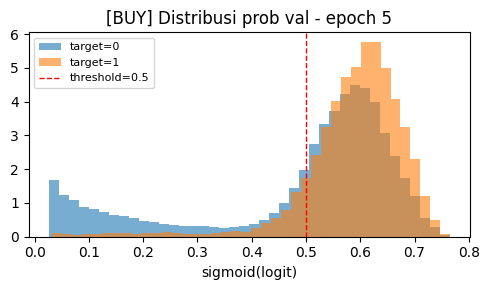

[BUY] Epoch:   6%|▌         | 6/100 [21:08<5:45:11, 220.34s/epoch, auc=0.6616, best=✓, fbeta=0.2904, loss=0.5998/0.7048, prec=0.2489]

  Epoch   6 | Loss 0.5998/0.7048 | Prec 0.2489 | F0.5 0.2904 | AUC 0.6616 | Sinyal 62192 | LR 1.00e-04 ← BEST
           prob val quantile [min/25/50/75/99/max] = [0.014/0.466/0.574/0.644/0.752/0.797]


[BUY] Epoch:   7%|▋         | 7/100 [26:20<6:27:57, 250.30s/epoch, auc=0.6642, best=✓, fbeta=0.2921, loss=0.5918/0.7227, prec=0.2507]

  Epoch   7 | Loss 0.5918/0.7227 | Prec 0.2507 | F0.5 0.2921 | AUC 0.6642 | Sinyal 61248 | LR 1.00e-04 ← BEST
           prob val quantile [min/25/50/75/99/max] = [0.008/0.451/0.586/0.670/0.779/0.821]


[BUY] Epoch:   8%|▊         | 8/100 [31:55<7:05:01, 277.19s/epoch, auc=0.6645, best=✓, fbeta=0.2956, loss=0.5845/0.7344, prec=0.2543]

  Epoch   8 | Loss 0.5845/0.7344 | Prec 0.2543 | F0.5 0.2956 | AUC 0.6645 | Sinyal 59089 | LR 1.00e-04 ← BEST
           prob val quantile [min/25/50/75/99/max] = [0.005/0.423/0.589/0.692/0.803/0.841]


... (8 outputs left out)

[SELL] Epoch:   4%|▍         | 4/100 [22:07<8:46:11, 328.87s/epoch, auc=0.6408, best=✓, fbeta=0.3019, loss=0.6142/0.6945, prec=0.2593]

  Epoch   4 | Loss 0.6142/0.6945 | Prec 0.2593 | F0.5 0.3019 | AUC 0.6408 | Sinyal 65814 | LR 1.00e-04 ← BEST
           prob val quantile [min/25/50/75/99/max] = [0.069/0.496/0.547/0.597/0.681/0.723]


[SELL] Epoch:   4%|▍         | 4/100 [26:41<8:46:11, 328.87s/epoch, auc=0.6480, best=✓, fbeta=0.3126, loss=0.6066/0.6686, prec=0.2719]

  Epoch   5 | Loss 0.6066/0.6686 | Prec 0.2719 | F0.5 0.3126 | AUC 0.6480 | Sinyal 55671 | LR 1.00e-04 ← BEST
           prob val quantile [min/25/50/75/99/max] = [0.036/0.461/0.530/0.594/0.707/0.763]


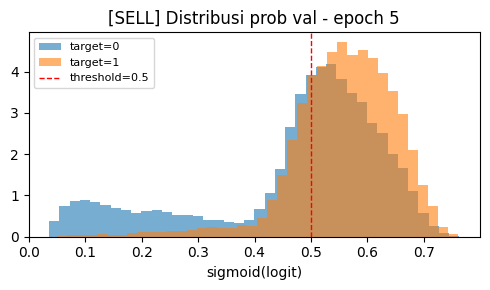

[SELL] Epoch:   6%|▌         | 6/100 [32:39<8:30:14, 325.68s/epoch, auc=0.6527, best=✓, fbeta=0.3200, loss=0.5989/0.6604, prec=0.2804]

  Epoch   6 | Loss 0.5989/0.6604 | Prec 0.2804 | F0.5 0.3200 | AUC 0.6527 | Sinyal 50863 | LR 1.00e-04 ← BEST
           prob val quantile [min/25/50/75/99/max] = [0.020/0.431/0.521/0.604/0.742/0.806]


[SELL] Epoch:   7%|▋         | 7/100 [38:14<8:29:30, 328.71s/epoch, auc=0.6542, best=✓, fbeta=0.3260, loss=0.5922/0.6526, prec=0.2881]

  Epoch   7 | Loss 0.5922/0.6526 | Prec 0.2881 | F0.5 0.3260 | AUC 0.6542 | Sinyal 46226 | LR 1.00e-04 ← BEST
           prob val quantile [min/25/50/75/99/max] = [0.013/0.398/0.506/0.607/0.772/0.835]


[SELL] Epoch:   8%|▊         | 8/100 [43:43<8:24:21, 328.93s/epoch, auc=0.6544, best=✓, fbeta=0.3320, loss=0.5855/0.6386, prec=0.2969]

  Epoch   8 | Loss 0.5855/0.6386 | Prec 0.2969 | F0.5 0.3320 | AUC 0.6544 | Sinyal 41090 | LR 1.00e-04 ← BEST
           prob val quantile [min/25/50/75/99/max] = [0.008/0.342/0.481/0.607/0.796/0.852]


[SELL] Epoch:   8%|▊         | 8/100 [49:09<9:25:23, 368.73s/epoch, auc=0.6512, best=1/1, fbeta=0.3297, loss=0.5791/0.6419, prec=0.2959]


  Epoch   9 | Loss 0.5791/0.6419 | Prec 0.2959 | F0.5 0.3297 | AUC 0.6512 | Sinyal 39814 | LR 1.00e-04 (patience 1/1)
           prob val quantile [min/25/50/75/99/max] = [0.006/0.319/0.470/0.613/0.816/0.868]
  Early stop epoch 9
  [SELL] ✅ Best state dipilih berdasarkan AUC=0.6544 (Prec=0.2969)

BUY  → best AUC=0.6645  | Precision @ best AUC=0.2543
SELL → best AUC=0.6544  | Precision @ best AUC=0.2969


In [19]:
import gc, joblib

print(f"\n{'='*65}")
print(f"Val: {split_info['val_start_time'].strftime('%Y-%m-%d')} → "
      f"{split_info['val_end_time'].strftime('%Y-%m-%d')}  "
      f"(train={split_info['n_train']:,} | val={split_info['n_val']:,})")
print(f"{'='*65}")

# ── BUY model ────────────────────────────────────────────────
print("\n[C3] Training BUY model...")
buy_model, buy_prec, buy_auc, buy_hist = train_binary_fold(
    split_info, feats_base, y_buy_tensor, "BUY",
    natr_tensor, adx_tensor, weight_tensor=weight_tensor,
    n_epochs=100, early_stop=1
)
joblib.dump(buy_model.to("cpu"), "buy_model.pkl")
buy_model.to(device)

# ── SELL model ───────────────────────────────────────────────
print("\n[C3] Training SELL model...")
sell_model, sell_prec, sell_auc, sell_hist = train_binary_fold(
    split_info, feats_base, y_sell_tensor, "SELL",
    natr_tensor, adx_tensor, weight_tensor=weight_tensor,
    n_epochs=100, early_stop=1
)
joblib.dump(sell_model.to("cpu"), "sell_model.pkl")
sell_model.to(device)

buy_models, sell_models = [buy_model], [sell_model]
folds = [split_info]   # alias biar cell 35/37/39 yang masih pakai `folds[idx]` tidak perlu diubah

print(f"\nBUY  → best AUC={buy_auc:.4f}  | Precision @ best AUC={buy_prec:.4f}")
print(f"SELL → best AUC={sell_auc:.4f}  | Precision @ best AUC={sell_prec:.4f}")

gc.collect()
if device == "cuda":
    torch.cuda.empty_cache()

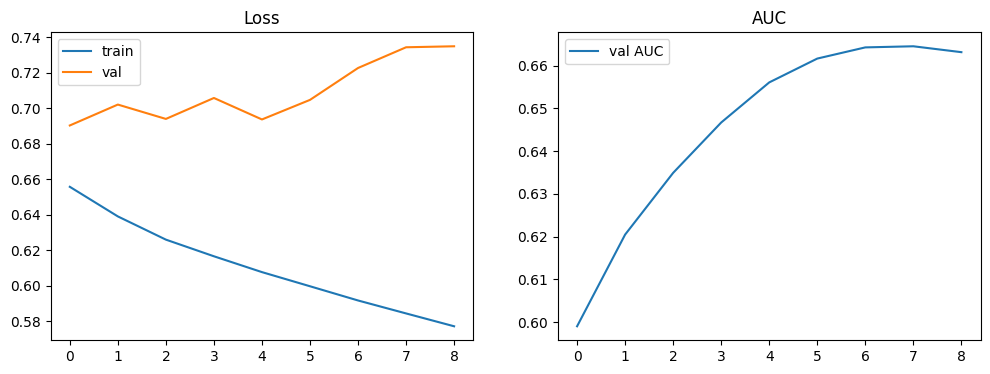

In [20]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(buy_hist["train_loss"], label="train")
axes[0].plot(buy_hist["val_loss"], label="val")
axes[0].set_title("Loss"); axes[0].legend()

axes[1].plot(buy_hist["val_auc"], label="val AUC")
axes[1].set_title("AUC"); axes[1].legend()
plt.show()

## 9. Ringkasan CV 

In [21]:
from sklearn.metrics import precision_recall_curve, fbeta_score

def calibrate_threshold(y_true, y_prob, target_precision=0.70,
                         min_signal_frac=0.01, beta=0.5, label=""):
    """
    Cari threshold optimal dari val set probabilities.
    - target_precision: precision minimum yang mau dijaga
    - min_signal_frac: minimal proporsi sampel yang harus jadi sinyal
                        (mencegah threshold "aman" tapi sinyalnya 0)
    """
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)
    # precision_recall_curve mengembalikan len(thresholds) = len(precisions) - 1
    precisions, recalls = precisions[:-1], recalls[:-1]

    n_total = len(y_true)
    min_signal = max(int(n_total * min_signal_frac), 1)

    # Kandidat 1: threshold minimum yang precision-nya >= target
    candidates = []
    for p, r, t in zip(precisions, recalls, thresholds):
        n_signal = int(r * y_true.sum())  # perkiraan jumlah sinyal
        if p >= target_precision and n_signal >= min_signal:
            candidates.append((t, p, r, n_signal))

    if candidates:
        # ambil threshold TERENDAH di antara kandidat (paling banyak sinyal
        # sambil tetap penuhi target precision)
        best_t, best_p, best_r, best_n = min(candidates, key=lambda x: x[0])
        reason = f"threshold terendah yang precision>={target_precision}"
    else:
        # fallback: precision target tidak pernah tercapai -> maksimalkan F-beta saja
        fbetas = [(2 if r+p==0 else (1+beta**2)*p*r/(beta**2*p+r+1e-12))
                  for p, r in zip(precisions, recalls)]
        best_idx = int(np.argmax(fbetas))
        best_t = thresholds[best_idx]
        best_p, best_r = precisions[best_idx], recalls[best_idx]
        best_n = int(best_r * y_true.sum())
        reason = f"precision>={target_precision} tidak pernah tercapai -> fallback ke F{beta} maksimal"

    print(f"[{label}] Threshold terkalibrasi = {best_t:.4f}  "
          f"(precision={best_p:.4f}, recall={best_r:.4f}, ~{best_n} sinyal)")
    print(f"          alasan: {reason}")
    return best_t

# ── Jalankan untuk BUY ──────────────────────────────────────
buy_thr = calibrate_threshold(all_targets_buy, all_probs_buy,
                               target_precision=0.70, label="BUY")

# ── Jalankan untuk SELL ─────────────────────────────────────
sell_thr = calibrate_threshold(all_targets_sell, all_probs_sell,
                                target_precision=0.70, label="SELL")

NameError: name 'all_targets_buy' is not defined

## 10. Evaluasi Detail — Fold Terbaik

Threshold = 0.70

              precision    recall  f1-score   support

     NOT BUY     0.8110    0.7297    0.7682    100384
         BUY     0.3261    0.4347    0.3726     30199

    accuracy                         0.6615    130583
   macro avg     0.5685    0.5822    0.5704    130583
weighted avg     0.6988    0.6615    0.6767    130583



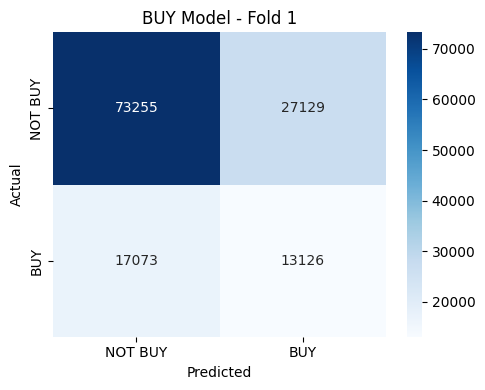

In [22]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Fold BUY terbaik
# best_buy_idx = np.argmax([r["best_prec"] for r in buy_reports])

best_model = buy_models[0]
best_fold  = folds[0]

val_ds = WindowDataset(
    feats_base, WINDOW_SIZE, best_fold["val_idx"],
    y_buy_tensor[best_fold["val_idx"]]
)

val_loader = DataLoader(
    val_ds,
    batch_size=1024,
    shuffle=False
)

best_model.eval()

all_preds = []
all_targets = []
all_probs = []

THRESHOLD = 0.70

with torch.no_grad():

    for xb, yb in val_loader:

        xb = xb.to(device)

        logits, conf = best_model(xb)

        # probabilitas BUY — single logit -> sigmoid
        prob = torch.sigmoid(logits).squeeze(1)

        pred = (prob >= THRESHOLD).long()

        all_probs.extend(prob.cpu().numpy())
        all_preds.extend(pred.cpu().numpy())
        all_targets.extend(yb.long().numpy())

print(f"Threshold = {THRESHOLD:.2f}")
print()

print(classification_report(
    all_targets,
    all_preds,
    target_names=["NOT BUY", "BUY"],
    digits=4,
    zero_division=0
))

cm = confusion_matrix(all_targets, all_preds)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NOT BUY","BUY"],
    yticklabels=["NOT BUY","BUY"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"BUY Model - Fold {best_fold['fold']}")
plt.tight_layout()
plt.show()


In [23]:
from sklearn.metrics import roc_auc_score

best_model.eval()

all_probs = []
all_targets = []

with torch.no_grad():

    for xb, yb in val_loader:

        xb = xb.to(device)

        logits, _ = best_model(xb)

        # probabilitas — single logit -> sigmoid
        probs = torch.sigmoid(logits).squeeze(1)

        all_probs.extend(probs.cpu().numpy())
        all_targets.extend(yb.numpy())

auc = roc_auc_score(all_targets, all_probs)

print(f"ROC AUC = {auc:.4f}")

ROC AUC = 0.6457


Threshold = 0.70

              precision    recall  f1-score   support

    NOT SELL     0.7753    0.9041    0.8348     99659
        SELL     0.3351    0.1558    0.2127     30924

    accuracy                         0.7269    130583
   macro avg     0.5552    0.5299    0.5237    130583
weighted avg     0.6711    0.7269    0.6875    130583



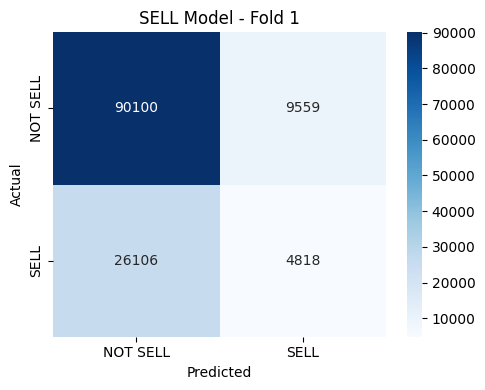

In [24]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Fold SELL terbaik
# best_sell_idx = np.argmax([r["best_prec"] for r in sell_reports])

best_model = sell_models[0]
best_fold  = folds[0]

val_ds = WindowDataset(
    feats_base, WINDOW_SIZE, best_fold["val_idx"],
    y_sell_tensor[best_fold["val_idx"]]
)

val_loader = DataLoader(
    val_ds,
    batch_size=1024,
    shuffle=False
)

best_model.eval()

all_probs = []
all_preds = []
all_targets = []

THRESHOLD = 0.70

with torch.no_grad():

    for xb, yb in val_loader:

        xb = xb.to(device)

        logits, conf = best_model(xb)

        # probabilitas SELL — single logit -> sigmoid
        prob = torch.sigmoid(logits).squeeze(1)

        pred = (prob >= THRESHOLD).long()

        all_probs.extend(prob.cpu().numpy())
        all_preds.extend(pred.cpu().numpy())
        all_targets.extend(yb.long().numpy())

print(f"Threshold = {THRESHOLD:.2f}\n")

print(classification_report(
    all_targets,
    all_preds,
    target_names=["NOT SELL", "SELL"],
    digits=4,
    zero_division=0
))

cm = confusion_matrix(all_targets, all_preds)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NOT SELL", "SELL"],
    yticklabels=["NOT SELL", "SELL"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"SELL Model - Fold {best_fold['fold']}")
plt.tight_layout()
plt.show()


In [25]:
from sklearn.metrics import roc_auc_score

best_model.eval()

all_probs = []
all_targets = []

with torch.no_grad():

    for xb, yb in val_loader:

        xb = xb.to(device)

        logits, _ = best_model(xb)

        # probabilitas — single logit -> sigmoid
        probs = torch.sigmoid(logits).squeeze(1)

        all_probs.extend(probs.cpu().numpy())
        all_targets.extend(yb.numpy())

auc = roc_auc_score(all_targets, all_probs)

print(f"ROC AUC = {auc:.4f}")

ROC AUC = 0.6255


In [26]:
# B1 + B2 — Threshold sweep untuk BUY dan SELL model terbaik
from sklearn.metrics import precision_score
import numpy as np

# Pakai fold terakhir sebagai evaluasi
best_buy_model  = buy_models[-1]
best_sell_model = sell_models[-1]
val_idx = folds[-1]["val_idx"]

# C2 — regime filter pada val set
regime_ok = regime_mask(natr_tensor[val_idx], adx_tensor[val_idx]).numpy()

val_ds   = WindowDataset(feats_base, WINDOW_SIZE, val_idx, y_tensor[val_idx])
val_loader = DataLoader(val_ds, batch_size=1024, shuffle=False)

# Kumpulkan logits dari kedua model
all_buy_probs, all_sell_probs, all_targets_list = [], [], []

best_buy_model.eval()
best_sell_model.eval()
with torch.no_grad():
    for xb, yb in val_loader:
        xb = xb.to(device)
        logits_buy,  _ = best_buy_model(xb)
        logits_sell, _ = best_sell_model(xb)
        all_buy_probs.append(torch.sigmoid(logits_buy).squeeze(1).cpu())
        all_sell_probs.append(torch.sigmoid(logits_sell).squeeze(1).cpu())
        all_targets_list.append(yb)

buy_probs   = torch.cat(all_buy_probs).numpy()
sell_probs  = torch.cat(all_sell_probs).numpy()
targets     = torch.cat(all_targets_list).numpy()

# Binarize targets untuk evaluasi
t_buy  = (targets == 1).astype(int)
t_sell = (targets == 2).astype(int)

print(f"{'THR_BUY':>8} {'THR_SELL':>9} {'Prec_BUY':>9} {'Prec_SELL':>10} {'N_BUY':>7} {'N_SELL':>7}")
print("-" * 58)

best_combo = None
best_avg   = 0.0

for thr_buy in [0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    for thr_sell in [0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
        for margin in [0.10, 0.15, 0.20]:
            # B1: prob threshold
            pred_buy  = (buy_probs  > thr_buy) .astype(int)
            pred_sell = (sell_probs > thr_sell).astype(int)

            # B2: zona abu-abu — margin tipis antara buy vs sell prob
            thin = np.abs(buy_probs - sell_probs) < margin
            pred_buy[thin]  = 0
            pred_sell[thin] = 0

            # C2: regime filter
            pred_buy[~regime_ok]  = 0
            pred_sell[~regime_ok] = 0

            # Hindari konflik: kalau dua-duanya 1, ambil yang lebih tinggi
            conflict = (pred_buy == 1) & (pred_sell == 1)
            pred_buy[conflict  & (buy_probs < sell_probs)] = 0
            pred_sell[conflict & (buy_probs >= sell_probs)] = 0

            n_buy  = pred_buy.sum()
            n_sell = pred_sell.sum()

            if n_buy < 5 or n_sell < 5:
                continue

            prec_buy  = precision_score(t_buy,  pred_buy,  zero_division=0)
            prec_sell = precision_score(t_sell, pred_sell, zero_division=0)
            avg       = (prec_buy + prec_sell) / 2

            if avg > best_avg:
                best_avg   = avg
                best_combo = (thr_buy, thr_sell, margin, prec_buy, prec_sell, n_buy, n_sell)

            if thr_buy == thr_sell and margin == 0.15:
                print(f"  {thr_buy:.2f}     {thr_sell:.2f}    {prec_buy:.4f}     {prec_sell:.4f}    {n_buy:5d}  {n_sell:5d}")

if best_combo:
    tb, ts, mg, pb, ps, nb_, ns = best_combo
    print(f"\n🏆 BEST COMBO: thr_buy={tb:.2f} thr_sell={ts:.2f} margin={mg:.2f}")
    print(f"   Prec BUY={pb:.4f}  Prec SELL={ps:.4f}  avg={best_avg:.4f}")
    print(f"   Sinyal BUY={nb_:,}  SELL={ns:,}")
    BUY_THR  = tb
    SELL_THR = ts
    MARGIN   = mg


 THR_BUY  THR_SELL  Prec_BUY  Prec_SELL   N_BUY  N_SELL
----------------------------------------------------------
  0.45     0.45    0.2268     0.2620    22037   3172
  0.50     0.50    0.2308     0.2789    21018   2750
  0.55     0.55    0.2375     0.2941    19361   2360
  0.60     0.60    0.2473     0.3068    16683   1874
  0.65     0.65    0.2622     0.3236    12921   1437
  0.70     0.70    0.2841     0.3422     8109   1014

🏆 BEST COMBO: thr_buy=0.70 thr_sell=0.70 margin=0.20
   Prec BUY=0.2844  Prec SELL=0.3568  avg=0.3206
   Sinyal BUY=5,587  SELL=569


## 11. Live Prediction

In [12]:
import joblib, time
import torch, torch.nn.functional as F

SYMBOL     = INSTRUMENT   # XAU/USD (Dukascopy)
WINDOW_INF = 96

BUY_THR = 0.70
SELL_THR = 0.70
MARGIN = 0.20

scaler_X = joblib.load("scaler.pkl")

# Load model terbaik (fold terakhir) — disimpan sebagai objek model penuh (.pkl)
inf_buy_model  = joblib.load("buy_model.pkl").to(device)
inf_sell_model = joblib.load("sell_model.pkl").to(device)
inf_buy_model.eval()
inf_sell_model.eval()

def get_latest_data(n_m5=700, n_htf=1000):
    # Fetch M5 data (lookback 10 hari — cukup untuk >700 candle M5 dengan margin weekend)
    df_live = fetch_dukascopy_recent(dukascopy_python.INTERVAL_MIN_5, lookback_days=10)
    if df_live.empty:
        raise ValueError("Tidak ada data M5 dari Dukascopy")
    df_live = create_features(df_live)
    if len(df_live) < WINDOW_INF:
        raise ValueError(f"Data M5 terlalu sedikit: {len(df_live)}")

    # Prepare M5 for merge
    df_live["time_dt"] = pd.to_datetime(df_live["time"], unit="s").astype("datetime64[ns]")
    df_live = df_live.sort_values("time_dt")
    df_live = df_live.tail(n_m5).reset_index(drop=True)

    # Fetch and process M15 data (lookback 25 hari — cukup untuk >1000 candle M15)
    m15_raw = fetch_dukascopy_recent(dukascopy_python.INTERVAL_MIN_15, lookback_days=25).tail(n_htf)
    if m15_raw.empty:
        raise ValueError("Tidak ada data M15 dari Dukascopy")
    m15_data_processed = create_features(m15_raw)
    m15_sub = prep_htf(m15_data_processed, "m15_", shift_minutes=15)

    # Fetch and process M30 data (lookback 40 hari — cukup untuk >1000 candle M30)
    m30_raw = fetch_dukascopy_recent(dukascopy_python.INTERVAL_MIN_30, lookback_days=40).tail(n_htf)
    if m30_raw.empty:
        raise ValueError("Tidak ada data M30 dari Dukascopy")
    m30_data_processed = create_features(m30_raw)
    m30_sub = prep_htf(m30_data_processed, "m30_", shift_minutes=30)

    # Fetch and process H1 data (lookback 75 hari — cukup untuk >1000 candle H1)
    h1_raw = fetch_dukascopy_recent(dukascopy_python.INTERVAL_HOUR_1, lookback_days=75).tail(n_htf)
    if h1_raw.empty:
        raise ValueError("Tidak ada data H1 dari Dukascopy")
    h1_data_processed = create_features(h1_raw)
    h1_sub = prep_htf(h1_data_processed, "h1_", shift_minutes=60)

    # Merge higher timeframe data to M5
    df_live = pd.merge_asof(df_live, m15_sub, on="time_dt", direction="backward")
    df_live = pd.merge_asof(df_live, m30_sub, on="time_dt", direction="backward")
    df_live = pd.merge_asof(df_live, h1_sub,  on="time_dt", direction="backward")

    # Drop any rows where HTF data might not have been available (e.g., very beginning of data)
    df_live = df_live.dropna()

    if df_live.empty:
        raise ValueError("Setelah menggabungkan HTF dan membersihkan NaN, DataFrame kosong.")

    # Ensure there are enough rows for the window and for slicing off the last candle
    if len(df_live) < WINDOW_INF + 1:
        raise ValueError(f"Tidak cukup data setelah preprocessing ({len(df_live)} rows) "
                         f"untuk WINDOW_INF ({WINDOW_INF}) + 1 candle.")

    return df_live.copy()[:-1]

def prepare_input(df_live):
    feats  = df_live[FEATURE_COLUMNS].values[-WINDOW_INF:]
    feats  = scaler_X.transform(feats)
    tensor = torch.tensor(
        feats.reshape(1, WINDOW_INF, N_FEATURES), dtype=torch.float32
    ).to(device)
    return tensor

def predict_v2():
    df_live = get_latest_data()

    # C2 — Regime filter: cek kondisi pasar terakhir
    last      = df_live.iloc[-1]
    last_natr = last["natr"]
    last_adx  = last.get("adx", last.get("atr_ratio", 99))

    NATR_MIN_INFERENCE = 0.0005

    if last_natr < NATR_MIN_INFERENCE:
        print(f"\u23f8 SKIP — NATR={last_natr:.5f} terlalu rendah (sideways)")
        return None, 0

    if last_adx < ADX_MIN:
        print(f"\u23f8 SKIP — ADX={last_adx:.2f} terlalu rendah (tidak trending)")
        return None, 0

    x = prepare_input(df_live)

    with torch.no_grad():
        logits_buy,  conf_buy  = inf_buy_model(x)
        logits_sell, conf_sell = inf_sell_model(x)

    prob_buy  = torch.sigmoid(logits_buy)[0, 0].item()
    prob_sell = torch.sigmoid(logits_sell)[0, 0].item()
    conf_b    = torch.sigmoid(conf_buy).item()
    conf_s    = torch.sigmoid(conf_sell).item()

    print(f"\U0001F4CA prob_buy={prob_buy:.3f} (conf={conf_b:.3f})  "
          f"prob_sell={prob_sell:.3f} (conf={conf_s:.3f})")

    # B1 — threshold gate
    signal_buy  = (prob_buy  > BUY_THR)  and (conf_b > 0.60)
    signal_sell = (prob_sell > SELL_THR) and (conf_s > 0.55)

    # B2 — zona abu-abu: margin terlalu tipis → HOLD
    if abs(prob_buy - prob_sell) < MARGIN:
        print(f"\u26aa HOLD — margin tipis ({abs(prob_buy-prob_sell):.3f} < {MARGIN})")
        return 0, max(prob_buy, prob_sell)

    # Konflik: dua-duanya tinggi → ambil yang lebih yakin
    if signal_buy and signal_sell:
        signal_buy  = prob_buy >= prob_sell
        signal_sell = not signal_buy

    if signal_buy:
        print(f"\U0001F4C8 BUY  — prob={prob_buy:.3f}  conf={conf_b:.3f}")
        return 1, prob_buy
    elif signal_sell:
        print(f"\U0001F4C9 SELL — prob={prob_sell:.3f}  conf={conf_s:.3f}")
        return 2, prob_sell
    else:
        print(f"\U0001F7E1 HOLD — prob_buy={prob_buy:.3f} prob_sell={prob_sell:.3f}")
        return 0, max(prob_buy, prob_sell)


In [13]:
import warnings
from pandas.errors import PerformanceWarning

warnings.filterwarnings("ignore")

In [18]:
import time, datetime

LABELS = {0: "🟡 HOLD", 1: "📈 BUY", 2: "📉 SELL"}

last_candle_time = None
index_i = 1

def seconds_until_next_m5_close(buffer_sec=5):
    """Hitung detik sampai candle M5 berikutnya close (kelipatan 5 menit),
    + buffer biar data dari Dukascopy sudah pasti ke-update dulu."""
    now = datetime.datetime.utcnow()
    minutes_to_next = 5 - (now.minute % 5)
    if minutes_to_next == 0:
        minutes_to_next = 5
    next_close = (now.replace(second=0, microsecond=0)
                  + datetime.timedelta(minutes=minutes_to_next))
    wait = (next_close - now).total_seconds() + buffer_sec
    return max(wait, buffer_sec)

print("🚀 Live prediction dimulai — hanya predict tiap candle M5 baru...\n")

while True:
    try:
        wait_sec = seconds_until_next_m5_close()
        print(f"⏳ Menunggu {wait_sec:.0f}s sampai candle M5 berikutnya close...")
        time.sleep(wait_sec)

        # Cek dulu apakah candle terakhir memang sudah berganti
        df_check = get_latest_data()
        current_candle_time = df_check["time_dt"].iloc[-1]

        if last_candle_time is not None and current_candle_time <= last_candle_time:
            # Data Dukascopy kadang belum ter-update pas persis di detik ke-0
            print(f"↩️  Candle belum baru ({current_candle_time}), retry 10s...")
            time.sleep(10)
            continue

        last_candle_time = current_candle_time

        signal, confidence = predict_v2()
        if signal is not None:
            print(f"#{index_i} | candle {current_candle_time} | "
                  f"{LABELS[signal]} | conf={confidence*100:.2f}%\n")
        index_i += 1

    except Exception as e:
        print(f"⚠️ Error: {e}")
        time.sleep(5)

🚀 Live prediction dimulai — hanya predict tiap candle M5 baru...

⏳ Menunggu 274s sampai candle M5 berikutnya close...


KeyboardInterrupt: 

In [19]:
LABELS   = {0: "🟡 HOLD", 1: "📈 BUY", 2: "📉 SELL"}
index_i  = 1

while True:
    try:
        signal, confidence = predict_v2()
        if signal is not None:
            print(f"#{index_i} | {LABELS[signal]} | conf={confidence*100:.2f}%\n")
        time.sleep(30)
    except Exception as e:
        print(f"Error: {e}")
        time.sleep(5)
    index_i += 1


INFO:DUKASCRIPT:current timestamp :2026-06-25T21:30:00


📊 prob_buy=0.704 (conf=0.474)  prob_sell=0.582 (conf=0.426)
⚪ HOLD — margin tipis (0.122 < 0.2)
#1 | 🟡 HOLD | conf=70.42%



KeyboardInterrupt: 

In [ ]:
import MetaTrader5 as mt5
import pandas as pd
import numpy as np
import joblib, time, datetime
import torch, torch.nn.functional as F

# ================= 1. INIT MT5 =================
# MT5_PATH     = r"C:\Program Files\MetaTrader 5\terminal64.exe"  # path terminal64.exe kamu
# MT5_LOGIN    = 12345678               # nomor akun MT5
# MT5_PASSWORD = "password_kamu"
# MT5_SERVER   = "NamaBroker-Server"    # cth: "Exness-MT5Trial"

def init_mt5():
    ok = mt5.initialize(
        # path=MT5_PATH,
        # login=MT5_LOGIN,
        # password=MT5_PASSWORD,
        # server=MT5_SERVER,
    )
    if not ok:
        raise RuntimeError(f"MT5 initialize() gagal, error = {mt5.last_error()}")
    acc = mt5.account_info()
    term = mt5.terminal_info()
    print(f"✅ Terhubung ke MT5 — Terminal: {term.name} | Akun: {acc.login} ({acc.server}) | Balance: {acc.balance}")

init_mt5()

SYMBOL = "XAUUSD"   # sesuaikan nama simbol di broker kamu (bisa "XAUUSD.m", "GOLD", dll)
if not mt5.symbol_select(SYMBOL, True):
    raise RuntimeError(f"Symbol {SYMBOL} tidak ditemukan / gagal di-select di Market Watch")

TF_M5  = mt5.TIMEFRAME_M5
TF_M15 = mt5.TIMEFRAME_M15
TF_M30 = mt5.TIMEFRAME_M30
TF_H1  = mt5.TIMEFRAME_H1

# ================= 2. LOAD MODEL & SCALER =================
WINDOW_INF = 96
BUY_THR    = 0.70
SELL_THR   = 0.70
MARGIN     = 0.20

scaler_X = joblib.load("scaler.pkl")
inf_buy_model  = joblib.load("buy_model_finetuned.pkl").to(device)
inf_sell_model = joblib.load("sell_model_finetuned.pkl").to(device)
inf_buy_model.eval()
inf_sell_model.eval()

# ================= 3. FETCH DATA DARI MT5 =================
def fetch_mt5_candles(timeframe, n_candles):
    """Ambil n_candles terakhir langsung dari MT5 (posisi 0 = candle paling
    baru, yang BISA JADI masih running/belum closed -- ditangani di
    get_latest_data() dengan cara buang baris terakhir)."""
    rates = mt5.copy_rates_from_pos(SYMBOL, timeframe, 0, n_candles)
    if rates is None or len(rates) == 0:
        raise ValueError(f"Gagal ambil data MT5 timeframe={timeframe} (error: {mt5.last_error()})")
    df = pd.DataFrame(rates)
    df["time"] = df["time"].astype("int64")  # sudah unix epoch detik
    for col in ("open", "high", "low", "close"):
        df[col] = df[col].astype("float32")
    df["tick_volume"] = pd.to_numeric(df["tick_volume"], downcast="integer")
    return df[["time", "open", "high", "low", "close", "tick_volume"]]

def get_latest_data(n_m5=700, n_htf=1000):
    df_live = fetch_mt5_candles(TF_M5, n_m5 + 5)
    df_live = create_features(df_live)
    if len(df_live) < WINDOW_INF:
        raise ValueError(f"Data M5 terlalu sedikit: {len(df_live)}")

    df_live["time_dt"] = pd.to_datetime(df_live["time"], unit="s").astype("datetime64[ns]")
    df_live = df_live.sort_values("time_dt")
    df_live = df_live.tail(n_m5).reset_index(drop=True)

    m15_raw = fetch_mt5_candles(TF_M15, n_htf + 5)
    m15_sub = prep_htf(create_features(m15_raw), "m15_", shift_minutes=15)

    m30_raw = fetch_mt5_candles(TF_M30, n_htf + 5)
    m30_sub = prep_htf(create_features(m30_raw), "m30_", shift_minutes=30)

    h1_raw = fetch_mt5_candles(TF_H1, n_htf + 5)
    h1_sub = prep_htf(create_features(h1_raw), "h1_", shift_minutes=60)

    df_live = pd.merge_asof(df_live, m15_sub, on="time_dt", direction="backward")
    df_live = pd.merge_asof(df_live, m30_sub, on="time_dt", direction="backward")
    df_live = pd.merge_asof(df_live, h1_sub,  on="time_dt", direction="backward")
    df_live = df_live.dropna()

    if df_live.empty:
        raise ValueError("Setelah merge HTF & dropna, DataFrame kosong.")
    if len(df_live) < WINDOW_INF + 1:
        raise ValueError(f"Tidak cukup data ({len(df_live)} rows) untuk WINDOW_INF+1.")

    # Buang candle terakhir -- itu candle M5 yang masih running/belum closed
    return df_live.copy()[:-1]

def prepare_input(df_live):
    feats  = df_live[FEATURE_COLUMNS].values[-WINDOW_INF:]
    feats  = scaler_X.transform(feats)
    tensor = torch.tensor(feats.reshape(1, WINDOW_INF, N_FEATURES), dtype=torch.float32).to(device)
    return tensor

# ================= 4. PREDIKSI =================
def predict_v2():
    # Auto-reconnect kalau koneksi MT5 putus
    if mt5.terminal_info() is None:
        print("⚠️ Koneksi MT5 putus, reconnect...")
        init_mt5()
        mt5.symbol_select(SYMBOL, True)

    df_live = get_latest_data()

    last      = df_live.iloc[-1]
    last_natr = last["natr"]
    last_adx  = last.get("adx", last.get("atr_ratio", 99))

    NATR_MIN_INFERENCE = 0.0005
    if last_natr < NATR_MIN_INFERENCE:
        print(f"⏸ SKIP — NATR={last_natr:.5f} terlalu rendah (sideways)")
        return None, 0
    if last_adx < ADX_MIN:
        print(f"⏸ SKIP — ADX={last_adx:.2f} terlalu rendah (tidak trending)")
        return None, 0

    x = prepare_input(df_live)
    with torch.no_grad():
        logits_buy,  conf_buy  = inf_buy_model(x)
        logits_sell, conf_sell = inf_sell_model(x)

    prob_buy  = torch.sigmoid(logits_buy)[0, 0].item()
    prob_sell = torch.sigmoid(logits_sell)[0, 0].item()
    conf_b    = torch.sigmoid(conf_buy).item()
    conf_s    = torch.sigmoid(conf_sell).item()

    print(f"📊 prob_buy={prob_buy:.3f} (conf={conf_b:.3f})  prob_sell={prob_sell:.3f} (conf={conf_s:.3f})")

    signal_buy  = (prob_buy  > BUY_THR)  and (conf_b > 0.60)
    signal_sell = (prob_sell > SELL_THR) and (conf_s > 0.55)

    if abs(prob_buy - prob_sell) < MARGIN:
        print(f"⚪ HOLD — margin tipis ({abs(prob_buy-prob_sell):.3f} < {MARGIN})")
        return 0, max(prob_buy, prob_sell)

    if signal_buy and signal_sell:
        signal_buy  = prob_buy >= prob_sell
        signal_sell = not signal_buy

    if signal_buy:
        print(f"📈 BUY  — prob={prob_buy:.3f}  conf={conf_b:.3f}")
        return 1, prob_buy
    elif signal_sell:
        print(f"📉 SELL — prob={prob_sell:.3f}  conf={conf_s:.3f}")
        return 2, prob_sell
    else:
        print(f"🟡 HOLD — prob_buy={prob_buy:.3f} prob_sell={prob_sell:.3f}")
        return 0, max(prob_buy, prob_sell)

# ================= 5. LOOP — PREDICT TIAP CANDLE M5 BARU =================
LABELS = {0: "🟡 HOLD", 1: "📈 BUY", 2: "📉 SELL"}
last_candle_time = None
index_i = 1

def get_last_closed_candle_time():
    """Posisi index=1 di copy_rates_from_pos = candle M5 terakhir yang
    SUDAH closed (index=0 selalu candle yang masih running)."""
    rates = mt5.copy_rates_from_pos(SYMBOL, TF_M5, 1, 1)
    if rates is None or len(rates) == 0:
        return None
    return pd.to_datetime(rates[0]["time"], unit="s")

def seconds_until_next_m5_close(buffer_sec=3):
    now = datetime.datetime.utcnow()
    minutes_to_next = 5 - (now.minute % 5)
    if minutes_to_next == 0:
        minutes_to_next = 5
    next_close = now.replace(second=0, microsecond=0) + datetime.timedelta(minutes=minutes_to_next)
    return max((next_close - now).total_seconds() + buffer_sec, buffer_sec)

print("🚀 Live prediction dimulai — hanya predict tiap candle M5 baru (MT5)...\n")

try:
    while True:
        try:
            wait_sec = seconds_until_next_m5_close()
            print(f"⏳ Menunggu {wait_sec:.0f}s sampai candle M5 berikutnya close...")
            time.sleep(wait_sec)

            current_candle_time = get_last_closed_candle_time()
            if current_candle_time is None:
                print("⚠️ Gagal ambil candle dari MT5, retry 5s...")
                time.sleep(5)
                continue

            if last_candle_time is not None and current_candle_time <= last_candle_time:
                print(f"↩️  Candle belum baru ({current_candle_time}), retry 5s...")
                time.sleep(5)
                continue

            last_candle_time = current_candle_time
            signal, confidence = predict_v2()
            if signal is not None:
                print(f"#{index_i} | candle {current_candle_time} | {LABELS[signal]} | conf={confidence*100:.2f}%\n")
            index_i += 1

        except Exception as e:
            print(f"⚠️ Error: {e}")
            time.sleep(5)

except KeyboardInterrupt:
    print("\n🛑 Dihentikan manual — menutup koneksi MT5...")
    mt5.shutdown()

✅ Terhubung ke MT5 — Terminal: HFM Metatrader 5 | Akun: 235019795 (HFMarketsGlobal-Demo4) | Balance: 166989458.86
🚀 Live prediction dimulai — hanya predict tiap candle M5 baru (MT5)...

⏳ Menunggu 130s sampai candle M5 berikutnya close...


In [ ]:
import torch
import torch.nn.functional as F

def predict_ensemble_binary(input_tensor,
                            models,
                            conf_threshold=0.55,
                            prob_threshold=0.70):
    """
    Ensemble prediction utk model binary (1 logit, BCEWithLogitsLoss).
    Rata-ratakan prob & confidence dari semua model dalam grup
    (mis. semua fold BUY, atau semua fold SELL), lalu gate dengan
    conf_threshold & prob_threshold.
    Return: pred (0/1 tensor), mean_prob, mean_conf
    """
    all_probs = []
    all_confs = []

    for m in models:
        m.eval()
        with torch.no_grad():
            logits, conf = m(input_tensor)            # logits: (B,1)
            probs        = torch.sigmoid(logits).squeeze(1)  # (B,)
            conf_prob    = torch.sigmoid(conf).squeeze(1)    # (B,)
            all_probs.append(probs)
            all_confs.append(conf_prob)

    mean_probs = torch.stack(all_probs).mean(dim=0)   # (B,)
    mean_confs = torch.stack(all_confs).mean(dim=0)   # (B,)

    pred = ((mean_probs >= prob_threshold) & (mean_confs >= conf_threshold)).long()

    return pred, mean_probs, mean_confs

pred_no = 129

# RAM-FRIENDLY: dulu ambil dari X_tensor (array window 3D penuh) yang
# sekarang sudah tidak disimpan. Window untuk 1 sampel dipotong langsung
# dari feats_base -- hanya WINDOW_SIZE x N_FEATURES, jauh lebih kecil.
start = n_total - pred_no
x_sample = torch.from_numpy(feats_base[start:start + WINDOW_SIZE].copy()) \
                .unsqueeze(0).to(device)

buy_pred,  buy_prob,  buy_conf  = predict_ensemble_binary(x_sample, buy_models,  conf_threshold=0.55, prob_threshold=0.70)
sell_pred, sell_prob, sell_conf = predict_ensemble_binary(x_sample, sell_models, conf_threshold=0.55, prob_threshold=0.70)

print(f"BUY  → pred={buy_pred.item()}  prob={buy_prob.item():.4f}  conf={buy_conf.item():.4f}")
print(f"SELL → pred={sell_pred.item()}  prob={sell_prob.item():.4f}  conf={sell_conf.item():.4f}")
print(x_sample.shape)


In [ ]:
range_history = 64 * pred_no

# 1. Ambil batasan masa lalunya dulu
df_historical = df["close"].iloc[-range_history:]

# 2. Ambil 64 data pertama dari potongan tersebut
df_plot = df_historical.iloc[:64]

df_actual = df_historical.iloc[64:64+6]

# Atau jika ingin mengambil 64 data terakhir dari potongan tersebut:
# df_plot = df_historical.tail(64)

plt.plot(df_plot)
plt.plot(df_actual)
plt.grid(True)
# Supaya x-axis nya tidak penuh angka timestamp mentah
plt.xticks(rotation=45) 
plt.show()

In [ ]:
# RAM-FRIENDLY: X_lgb dulu diambil dari X[:, -1, :] (baris terakhir tiap
# window di array 3D yang sekarang sudah tidak dibuat). Baris terakhir
# window sampel ke-i ada di feats_base pada posisi (i + WINDOW_SIZE - 1),
# jadi cukup slice feats_base langsung -- tanpa perlu membangun X sama
# sekali.
X_lgb = feats_base[WINDOW_SIZE - 1 : WINDOW_SIZE - 1 + n_total]


In [ ]:
print(np.unique(y))
print(y.shape)

In [ ]:
y_buy = (y == 1).astype(np.int32)

model = lgb.LGBMClassifier(
    objective="binary",
    metric="auc",
    n_estimators=500,
    learning_rate=0.03,
    random_state=42
)

model.fit(X_lgb, y_buy)

In [ ]:
importance = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "importance": model.booster_.feature_importance(
        importance_type="gain"
    )
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

import pandas as pd

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

print(importance)

In [ ]:
y_sell = (y == 2).astype(np.int32)

model.fit(X_lgb, y_sell)

In [ ]:
importance = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "importance": model.booster_.feature_importance(
        importance_type="gain"
    )
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

print(importance)

In [ ]:
import matplotlib.pyplot as plt

importance = importance.head(30)

plt.figure(figsize=(10,10))
plt.barh(
    importance["feature"],
    importance["importance"]
)
plt.gca().invert_yaxis()
plt.show()